# Copper VirtualFoundry1 DoE Notebook

This notebook prepares the first copper screening matrix. The factor levels are stored in `copper_doe_levels.json`, so the low, center, and high values can be changed there without editing the design code.

## FFD Matrices

### Copper Definitive Screening Design

This is a 13-run Definitive Screening Design for five continuous factors. The coded matrix uses `-1` for low, `0` for center, and `+1` for high. Line width is fixed at 0.62 mm and wall order is fixed at inner/outer.

In [65]:
from pathlib import Path
import importlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from notebook_plot_saver import configure_notebook_plot_saving

PLOT_OUTPUT_ROOT = configure_notebook_plot_saving(
    "notebook_figures", default_series="07_Copper_VirtualFoundry1"
)
FILAMENT_TYPE = "VF1"
_saved_plot_show = plt.show

def _show_with_filament_type(*args, **kwargs):
    for figure_number in plt.get_fignums():
        figure = plt.figure(figure_number)
        title_artist = figure._suptitle
        if title_artist is None:
            title_artist = next(
                (axis.title for axis in figure.axes if axis.get_title()),
                None,
            )
        if title_artist is None:
            continue
        title = title_artist.get_text()
        if FILAMENT_TYPE in title:
            continue
        if "Copper" in title:
            title = title.replace("Copper", f"Copper {FILAMENT_TYPE}", 1)
        else:
            title = f"{FILAMENT_TYPE} - {title}"
        title_artist.set_text(title)
    return _saved_plot_show(*args, **kwargs)

_show_with_filament_type._doe_original_show = getattr(
    _saved_plot_show, "_doe_original_show", _saved_plot_show
)
plt.show = _show_with_filament_type
SIGNIFICANCE_ALPHA = 0.05
print(f"Notebook figures will be saved under: {PLOT_OUTPUT_ROOT}")

import copper_doe_analysis
importlib.reload(copper_doe_analysis)

from copper_doe_analysis import (
    build_copper_anova_table,
    build_copper_desirability_table,
    build_copper_paired_measurement_table,
    build_copper_term_anova_table,
    build_copper_term_significance_table,
    default_dsd_terms,
    fit_copper_response_model,
    plot_copper_actual_vs_predicted,
    plot_copper_anova,
    plot_copper_contours,
    plot_copper_curvature,
    plot_copper_desirability,
    plot_copper_interactions,
    plot_copper_main_effects,
    plot_copper_measurement_correlation,
    plot_copper_normal_effects,
    plot_copper_pareto,
    plot_copper_residuals,
    response_label,
    response_unit,
    plot_copper_weight_measurements,
)


CONFIG_PATH = Path("copper_doe_levels.json")
if not CONFIG_PATH.exists():
    CONFIG_PATH = Path("3D_Printing_Project") / CONFIG_PATH

with CONFIG_PATH.open("r", encoding="utf-8") as config_file:
    copper_config = json.load(config_file)

copper_factors = copper_config["factors"]
copper_factor_names = [factor["name"] for factor in copper_factors]
copper_factor_levels = {
    factor["name"]: {-1: factor["low"], 0: factor["center"], 1: factor["high"]}
    for factor in copper_factors
}

copper_fixed_settings = copper_config["fixed_settings"]
copper_run_labels = [f"T{i}" for i in range(1, 14)]

Notebook figures will be saved under: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\notebook_figures


The table below is read directly from the JSON file. Change the JSON values if the screening range needs to be adjusted.

In [66]:
copper_level_table = pd.DataFrame(
    [
        {
            "Factor": factor["display_name"],
            "Column": factor["name"],
            "Low (-1)": factor["low"],
            "Center (0)": factor["center"],
            "High (+1)": factor["high"],
            "Unit": factor["unit"],
        }
        for factor in copper_factors
    ]
)

display(copper_level_table)
display(pd.DataFrame([copper_fixed_settings]))

,Factor,Column,Low (-1),Center (0),High (+1),Unit
0,Layer height,A_layer_height_mm,0.18,0.2,0.22,mm
1,Flow ratio,B_flow_ratio,1.18,1.2,1.22,
2,Nozzle temperature,C_nozzle_temp_C,215.00,220.0,225.00,deg C
3,Speed,D_speed_mm_s,60.00,70.0,80.00,mm/s
4,Infill,E_infill_percent,90.00,92.5,95.00,%


,line_width_mm,wall_order
0,0.62,inner/outer


The coded matrix is the actual Definitive Screening Design. The 13 runs come from the five-factor DSD structure: paired high/low rows plus one center row. This keeps the main effects balanced while still allowing curvature screening.

In [67]:
copper_dsd_coded_values = [
    [ 1,  1,  1,  1,  1],
    [ 0,  1, -1, -1,  1],
    [ 1,  0,  1, -1, -1],
    [-1,  1,  0,  1, -1],
    [-1, -1,  1,  0,  1],
    [ 1, -1, -1,  1,  0],
    [-1, -1, -1, -1, -1],
    [ 0, -1,  1,  1, -1],
    [-1,  0, -1,  1,  1],
    [ 1, -1,  0, -1,  1],
    [ 1,  1, -1,  0, -1],
    [-1,  1,  1, -1,  0],
    [ 0,  0,  0,  0,  0],
]

copper_dsd_coded = pd.DataFrame(
    copper_dsd_coded_values,
    columns=copper_factor_names,
)
copper_dsd_coded.insert(0, "Run", copper_run_labels)

display(copper_dsd_coded)

,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent
0,T1,1,1,1,1,1
1,T2,0,1,-1,-1,1
2,T3,1,0,1,-1,-1
3,T4,-1,1,0,1,-1
4,T5,-1,-1,1,0,1
5,T6,1,-1,-1,1,0
6,T7,-1,-1,-1,-1,-1
7,T8,0,-1,1,1,-1
8,T9,-1,0,-1,1,1
9,T10,1,-1,0,-1,1


The real matrix below converts each coded level to the printer setting from the JSON file. The fixed settings are added to every run because they are intentionally not part of the screening design.

In [68]:
def coded_to_real_value(factor_name, coded_value):
    return copper_factor_levels[factor_name][int(coded_value)]


copper_dsd_real = copper_dsd_coded.copy()
for factor_name in copper_factor_names:
    copper_dsd_real[factor_name] = copper_dsd_real[factor_name].map(
        lambda coded_value: coded_to_real_value(factor_name, coded_value)
    )

for setting_name, setting_value in copper_fixed_settings.items():
    copper_dsd_real[setting_name] = setting_value

display(copper_dsd_real)

,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,line_width_mm,wall_order
0,T1,0.22,1.22,225,80,95.0,0.62,inner/outer
1,T2,0.20,1.22,215,60,95.0,0.62,inner/outer
2,T3,0.22,1.20,225,60,90.0,0.62,inner/outer
3,T4,0.18,1.22,220,80,90.0,0.62,inner/outer
4,T5,0.18,1.18,225,70,95.0,0.62,inner/outer
5,T6,0.22,1.18,215,80,92.5,0.62,inner/outer
6,T7,0.18,1.18,215,60,90.0,0.62,inner/outer
7,T8,0.20,1.18,225,80,90.0,0.62,inner/outer
8,T9,0.18,1.20,215,80,95.0,0.62,inner/outer
9,T10,0.22,1.18,220,60,95.0,0.62,inner/outer


## Measurement Table

The measured masses and print notes are stored in `copper_doe_measurements.json`. Edit that JSON file when new copper runs are measured.

In [69]:
MEASUREMENT_PATH = Path("copper_doe_measurements.json")
if not MEASUREMENT_PATH.exists():
    MEASUREMENT_PATH = Path("3D_Printing_Project") / MEASUREMENT_PATH

with MEASUREMENT_PATH.open("r", encoding="utf-8") as measurement_file:
    copper_measurement_config = json.load(measurement_file)

COPPER_FILAMENT_DENSITY_G_CM3 = copper_measurement_config["filament_density_g_cm3"]
if COPPER_FILAMENT_DENSITY_G_CM3 <= 0:
    raise ValueError("Copper filament density must be greater than zero.")

copper_measurements = pd.DataFrame(copper_measurement_config["runs"])
copper_measurements = copper_measurements.rename(columns={"run": "Run"})

copper_density = pd.to_numeric(copper_measurements["density_g_cm3"], errors="coerce")
calculated_relative_density = copper_density / COPPER_FILAMENT_DENSITY_G_CM3 * 100
reported_relative_density = pd.to_numeric(
    copper_measurements["relative_density_percent"],
    errors="coerce",
)
copper_measurements["relative_density_percent"] = (
    reported_relative_density.fillna(calculated_relative_density)
)
copper_measurements["porosity_percent"] = (
    100 - copper_measurements["relative_density_percent"]
)

factor_cols = [factor["name"] for factor in copper_config["factors"]]
response_cols = [
    "weight_measurements_g",
    "weight_g",
    "weight_in_air_g",
    "weight_in_water_g",
    "volume_cm3",
    "notes",
    "density_g_cm3",
    "geometric_density_g_cm3",
    "avg_density_g_cm3",
    "relative_density_percent",
    "porosity_percent",
    "leakage_rate",
    "log_leakage_rate",
    "visible_clumping_score",
]

planned_measurements = copper_measurements[
    copper_measurements["Run"].isin(copper_dsd_real["Run"])
]
copper_measurement_table = copper_dsd_real.merge(
    planned_measurements[["Run", *response_cols]],
    on="Run",
    how="left",
)

extra_measurements = copper_measurements[
    ~copper_measurements["Run"].isin(copper_dsd_real["Run"])
].copy()
if not extra_measurements.empty:
    extra_columns = ["Run", *factor_cols, *response_cols]
    for column in extra_columns:
        if column not in extra_measurements:
            extra_measurements[column] = pd.NA
    copper_measurement_table = pd.concat(
        [copper_measurement_table, extra_measurements[extra_columns]],
        ignore_index=True,
    )

MEASUREMENT_OFFSET_EXCLUDED_RUNS = ["T10.1", "T16", "T17"]
offset_calibration_pairs = build_copper_paired_measurement_table(
    copper_measurement_table,
    exclude_runs=MEASUREMENT_OFFSET_EXCLUDED_RUNS,
)
MEASUREMENT_1_OFFSET_G = offset_calibration_pairs[
    "offset_2_minus_1_g"
].mean()

display(copper_measurement_table)


,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,line_width_mm,wall_order,weight_measurements_g,weight_g,...,volume_cm3,notes,density_g_cm3,geometric_density_g_cm3,avg_density_g_cm3,relative_density_percent,porosity_percent,leakage_rate,log_leakage_rate,visible_clumping_score
0,T1,0.22,1.22,225.0,80.0,95.0,0.62,inner/outer,"[47.429, 50.093]",48.7610,...,10.20,many blobs.,4.62,4.47,4.54,95.40,4.60,None,None,None
1,T2,0.20,1.22,215.0,60.0,95.0,0.62,inner/outer,"[47.305, 49.921]",48.6130,...,10.13,still many blobs which fall off. Prime tower s...,4.70,4.58,4.64,97.02,2.98,None,None,None
2,T3,0.22,1.20,225.0,60.0,90.0,0.62,inner/outer,"[44.554, 47.013]",45.7835,...,10.08,"less material adhering to nozzle, line missing...",4.45,4.33,4.39,91.84,8.16,None,None,None
3,T4,0.18,1.22,220.0,80.0,90.0,0.62,inner/outer,"[44.932, 47.422]",46.1770,...,10.18,"again more clumping, but not excessive",4.44,4.36,4.40,91.75,8.25,None,None,None
4,T5,0.18,1.18,225.0,70.0,95.0,0.62,inner/outer,"[45.106, 47.608]",46.3570,...,10.09,,4.50,4.37,4.44,92.92,7.08,None,None,None
5,T6,0.22,1.18,215.0,80.0,92.5,0.62,inner/outer,"[44.484, 46.951]",45.7175,...,10.11,less stuff on nozzle.,4.43,4.30,4.37,91.44,8.56,None,None,None
6,T7,0.18,1.18,215.0,60.0,90.0,0.62,inner/outer,"[43.286, 45.687]",44.4865,...,10.12,looks surprisingly good but holes between infi...,4.30,4.20,4.25,88.90,11.10,None,None,None
7,T8,0.20,1.18,225.0,80.0,90.0,0.62,inner/outer,"[43.294, 45.694]",44.4940,...,10.05,wieder mehr an der nozzle. Viel zwischenwand u...,4.33,4.23,4.28,89.48,10.52,None,None,None
8,T9,0.18,1.20,215.0,80.0,95.0,0.62,inner/outer,"[46.487, 49.066]",47.7765,...,10.18,,4.59,4.48,4.54,94.89,5.11,None,None,None
9,T10,0.22,1.18,220.0,60.0,95.0,0.62,inner/outer,"[45.299, 47.812]",46.5555,...,10.10,,4.51,4.40,4.46,93.23,6.77,None,None,None


## Mass Measurements


### Copper Mass Measurements: T1-T17

This plot presents the complete `T1`-`T17` measurement sequence, including the available repeat specimens.

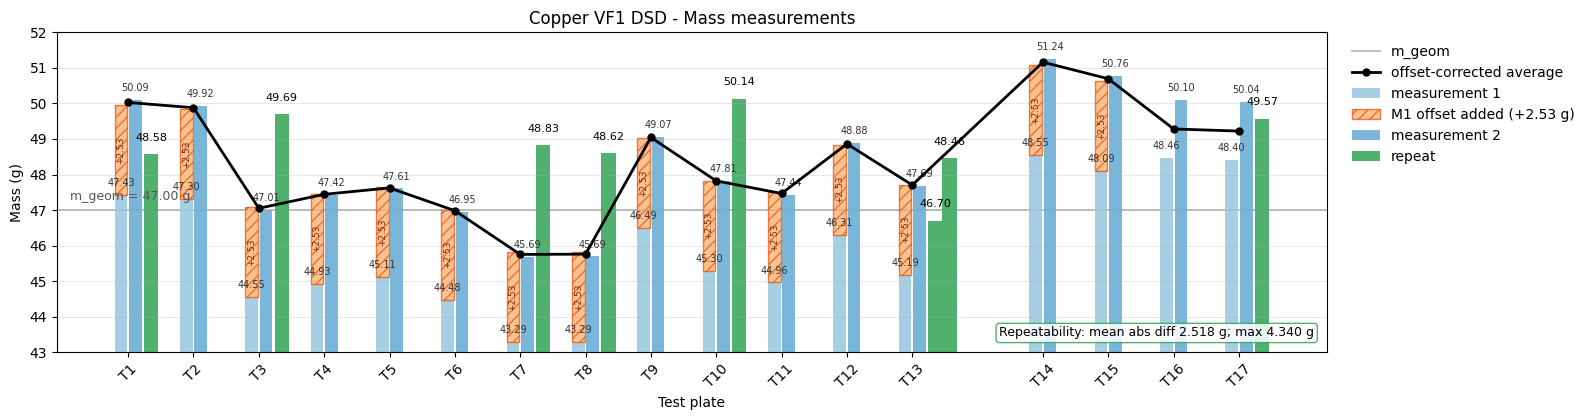

In [70]:
plot_copper_weight_measurements(
    copper_measurement_table,
    response="weight_g",
    measurement_1_offset_g=MEASUREMENT_1_OFFSET_G,
    offset_excluded_runs=MEASUREMENT_OFFSET_EXCLUDED_RUNS,
    base_runs=[f"T{i}" for i in range(1, 14)],
    repeat_runs=["T1.1", "T3.2", "T7.2", "T8.2", "T10.1", "T13.1", "T13.2", "T17.1"],
    extra_runs=[f"T{i}" for i in range(14, 18)],
    y_min=43,
    y_max=52,
    value_digits=2,
    reference_weight_g=47,
    reference_label="m_geom",
    show_weight_line=True,
)


### Offset and Correlation Between Repeated Measurements

The offset is defined as **measurement 2 minus measurement 1**. The correlation panel measures association, while the offset panel checks whether the difference is consistent across specimens.

,Run,measurement_1_g,measurement_2_g,offset_2_minus_1_g
0,T1,47.429,50.093,2.664
1,T2,47.305,49.921,2.616
2,T3,44.554,47.013,2.459
3,T4,44.932,47.422,2.490
4,T5,45.106,47.608,2.502
5,T6,44.484,46.951,2.467
6,T7,43.286,45.687,2.401
7,T8,43.294,45.694,2.400
8,T9,46.487,49.066,2.579
9,T10,45.299,47.812,2.513


,value
paired specimens,16.000
mean offset (g),2.532
median offset (g),2.509
offset standard deviation (g),0.091
minimum offset (g),2.400
maximum offset (g),2.689
Pearson correlation r,1.000


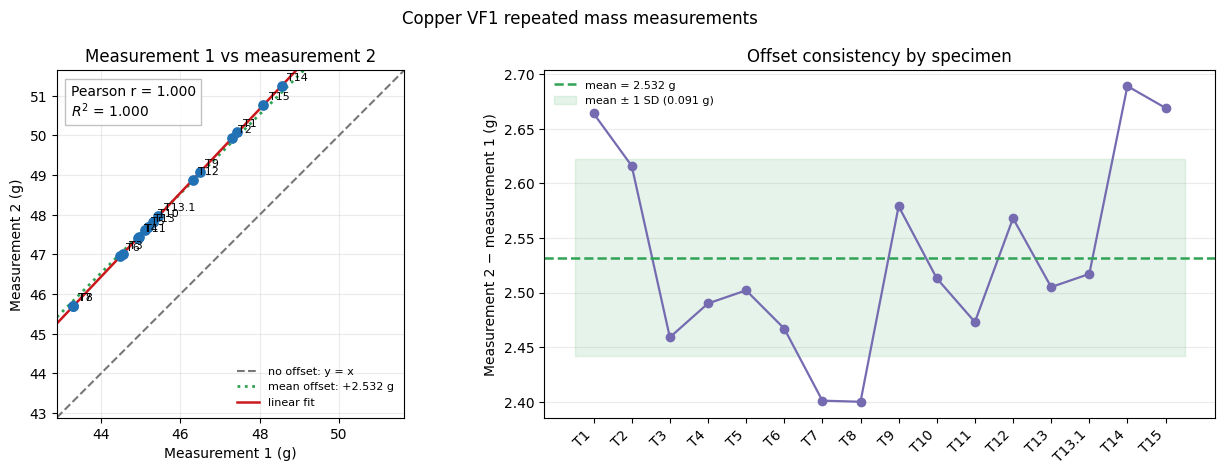

,Run,measurement_1_g,measurement_2_g,offset_2_minus_1_g
0,T1,47.429,50.093,2.664
1,T2,47.305,49.921,2.616
2,T3,44.554,47.013,2.459
3,T4,44.932,47.422,2.490
4,T5,45.106,47.608,2.502
5,T6,44.484,46.951,2.467
6,T7,43.286,45.687,2.401
7,T8,43.294,45.694,2.400
8,T9,46.487,49.066,2.579
9,T10,45.299,47.812,2.513


In [71]:
copper_paired_measurements = offset_calibration_pairs.copy()

offsets = copper_paired_measurements["offset_2_minus_1_g"]
measurement_correlation = copper_paired_measurements[
    ["measurement_1_g", "measurement_2_g"]
].corr().iloc[0, 1]
offset_summary = pd.Series({
    "paired specimens": len(copper_paired_measurements),
    "mean offset (g)": offsets.mean(),
    "median offset (g)": offsets.median(),
    "offset standard deviation (g)": offsets.std(ddof=1),
    "minimum offset (g)": offsets.min(),
    "maximum offset (g)": offsets.max(),
    "Pearson correlation r": measurement_correlation,
}, name="value")

display(copper_paired_measurements.round(3))
display(offset_summary.to_frame().round(3))
plot_copper_measurement_correlation(
    copper_measurement_table,
    exclude_runs=MEASUREMENT_OFFSET_EXCLUDED_RUNS,
)


## Density Measurements


### Copper Hydrostatic Mass, Volume, and Density Measurements

The mass, volume, and two-panel density figures use the T1-T17 specimen sequence, including the T13 repeats where available.


,Run,weight_in_air_g,weight_in_water_g,volume_cm3,density_g_cm3,relative_density_percent,porosity_percent
0,T1,47.09,10.18,10.20,4.62,95.40,4.60
1,T2,47.56,10.11,10.13,4.70,97.02,2.98
2,T3,44.80,10.06,10.08,4.45,91.84,8.16
3,T4,45.20,10.16,10.18,4.44,91.75,8.25
4,T5,45.37,10.07,10.09,4.50,92.92,7.08
5,T6,44.74,10.09,10.11,4.43,91.44,8.56
6,T7,43.54,10.10,10.12,4.30,88.90,11.10
7,T8,43.52,10.03,10.05,4.33,89.48,10.52
8,T9,46.75,10.16,10.18,4.59,94.89,5.11
9,T10,45.57,10.08,10.10,4.51,93.23,6.77


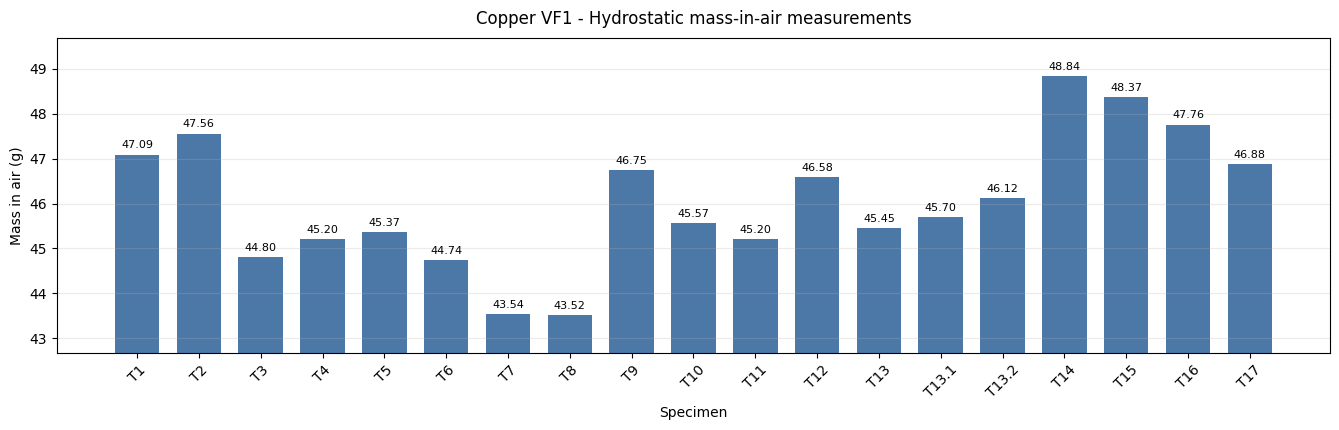

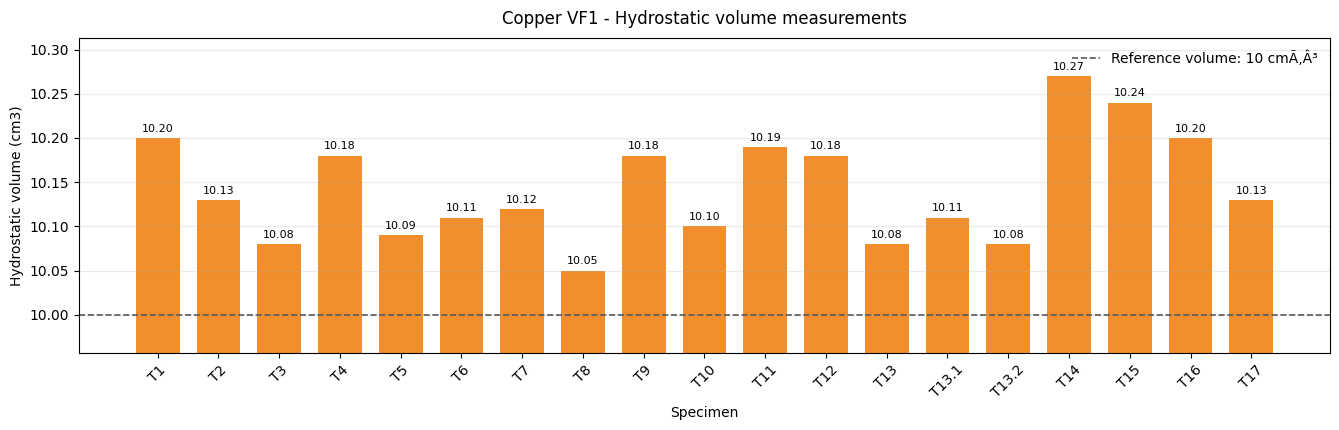

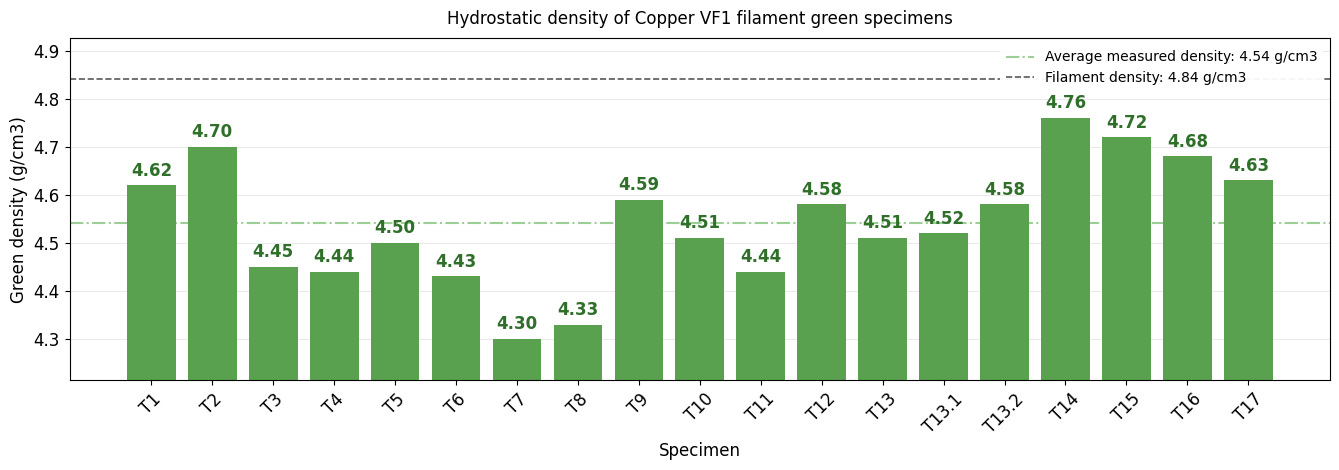

In [72]:
COPPER_HYDROSTATIC_COLUMNS = [
    "weight_in_air_g",
    "weight_in_water_g",
    "volume_cm3",
    "density_g_cm3",
    "relative_density_percent",
    "porosity_percent",
]

copper_hydrostatic_measurements = copper_measurements[[
    "Run",
    *COPPER_HYDROSTATIC_COLUMNS,
]].copy()
for column in COPPER_HYDROSTATIC_COLUMNS:
    copper_hydrostatic_measurements[column] = pd.to_numeric(
        copper_hydrostatic_measurements[column], errors="coerce"
    )
COPPER_HYDROSTATIC_PLOT_RUNS = [
    *[f"T{i}" for i in range(1, 14)],
    "T13.1", "T13.2",
    *[f"T{i}" for i in range(14, 18)],
]
copper_hydrostatic_measurements = (
    copper_hydrostatic_measurements
    .set_index("Run")
    .reindex(COPPER_HYDROSTATIC_PLOT_RUNS)
    .reset_index()
    .dropna(subset=["density_g_cm3"])
)

display(copper_hydrostatic_measurements.round({
    "weight_in_air_g": 3,
    "weight_in_water_g": 3,
    "volume_cm3": 3,
    "density_g_cm3": 3,
    "relative_density_percent": 2,
    "porosity_percent": 2,
}))

def plot_hydrostatic_measurement(
    data, response, y_label, title, color, min_padding,
    reference_value=None, reference_label=None,
):
    plot_df = data.dropna(subset=[response]).copy()
    values = plot_df[response]
    lower_bound = min(values.min(), reference_value) if reference_value is not None else values.min()
    upper_bound = max(values.max(), reference_value) if reference_value is not None else values.max()
    padding = max((upper_bound - lower_bound) * 0.16, min_padding)
    fig_width = max(13.5, 0.62 * len(plot_df))
    fig, ax = plt.subplots(figsize=(fig_width, 4.4))
    bars = ax.bar(plot_df["Run"], values, color=color, width=0.72)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    if reference_value is not None:
        ax.axhline(
            reference_value, color="0.35", linestyle="--", linewidth=1.2,
            label=reference_label,
        )
        ax.legend(frameon=False, loc="upper right")
    ax.set_xlabel("Specimen")
    ax.set_ylabel(y_label)
    ax.set_ylim(lower_bound - padding, upper_bound + padding)
    ax.set_title(title, pad=10)
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", labelrotation=45)
    plt.tight_layout()
    plt.show(block=False)

plot_hydrostatic_measurement(
    copper_hydrostatic_measurements,
    response="weight_in_air_g",
    y_label="Mass in air (g)",
    title="Copper - Hydrostatic mass-in-air measurements",
    color="#4c78a8",
    min_padding=0.50,
)
plot_hydrostatic_measurement(
    copper_hydrostatic_measurements,
    response="volume_cm3",
    y_label="Hydrostatic volume (cm3)",
    title="Copper - Hydrostatic volume measurements",
    color="#f28e2b",
    min_padding=0.04,
    reference_value=10.00,
    reference_label="Reference volume: 10 cmÃ‚Â³",
)
COPPER_GREEN_DENSITY_PLOT_RUNS = [
    *[f"T{i}" for i in range(1, 14)],
    "T13.1", "T13.2",
    *[f"T{i}" for i in range(14, 18)],
]
green_density_measurements = (
    copper_measurements[["Run", "density_g_cm3", "relative_density_percent"]]
    .set_index("Run")
    .reindex(COPPER_GREEN_DENSITY_PLOT_RUNS)
    .reset_index()
)
for column in ["density_g_cm3", "relative_density_percent"]:
    green_density_measurements[column] = pd.to_numeric(
        green_density_measurements[column], errors="coerce"
    )
green_density_measurements = green_density_measurements.dropna(
    subset=["density_g_cm3", "relative_density_percent"]
)

PLOT_FONT_SIZE = 12
LEGEND_FONT_SIZE = 10

fig_width = max(13.5, 0.62 * len(green_density_measurements))
fig, ax = plt.subplots(figsize=(fig_width, 4.8))
run_labels = green_density_measurements["Run"]
density_values = green_density_measurements["density_g_cm3"]
average_density = density_values.mean()

density_min = density_values.min()
density_max = max(density_values.max(), COPPER_FILAMENT_DENSITY_G_CM3)
density_pad = max((density_max - density_min) * 0.16, 0.08)

density_bars = ax.bar(
    run_labels, density_values, color="#59a14f", zorder=2
)
ax.axhline(
    average_density,
    color="#9bcf95",
    linestyle="-.",
    linewidth=1.5,
    label=f"Average measured density: {average_density:.2f} g/cm3",
    zorder=1,
)
ax.axhline(
    COPPER_FILAMENT_DENSITY_G_CM3,
    color="0.35",
    linestyle="--",
    linewidth=1.2,
    label="Filament density: 4.84 g/cm3",
    zorder=1,
)
ax.bar_label(
    density_bars, fmt="%.2f", padding=4, fontsize=PLOT_FONT_SIZE,
    fontweight="bold", color="#2F6F2A",
)
ax.set_xlabel("Specimen", fontsize=PLOT_FONT_SIZE)
ax.set_ylabel("Green density (g/cm3)", fontsize=PLOT_FONT_SIZE)
ax.set_ylim(density_min - density_pad, density_max + density_pad)
ax.set_title(
    "Hydrostatic density of Copper VF1 filament green specimens",
    pad=10, fontsize=PLOT_FONT_SIZE,
)
ax.legend(
    loc="upper right", facecolor="white", framealpha=0.95,
    edgecolor="none", fontsize=LEGEND_FONT_SIZE,
)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="both", labelsize=PLOT_FONT_SIZE)
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show(block=False)


#### Copper Mass, Volume, and Density Correlations

These plots compare the offset-corrected precision-scale mean mass with hydrostatic volume and Archimedes density. The additional plot compares Archimedes density with geometric density from caliper dimensions. Only specimens with the required measurements are included. Pearson `r` describes the strength and direction of each linear relationship.


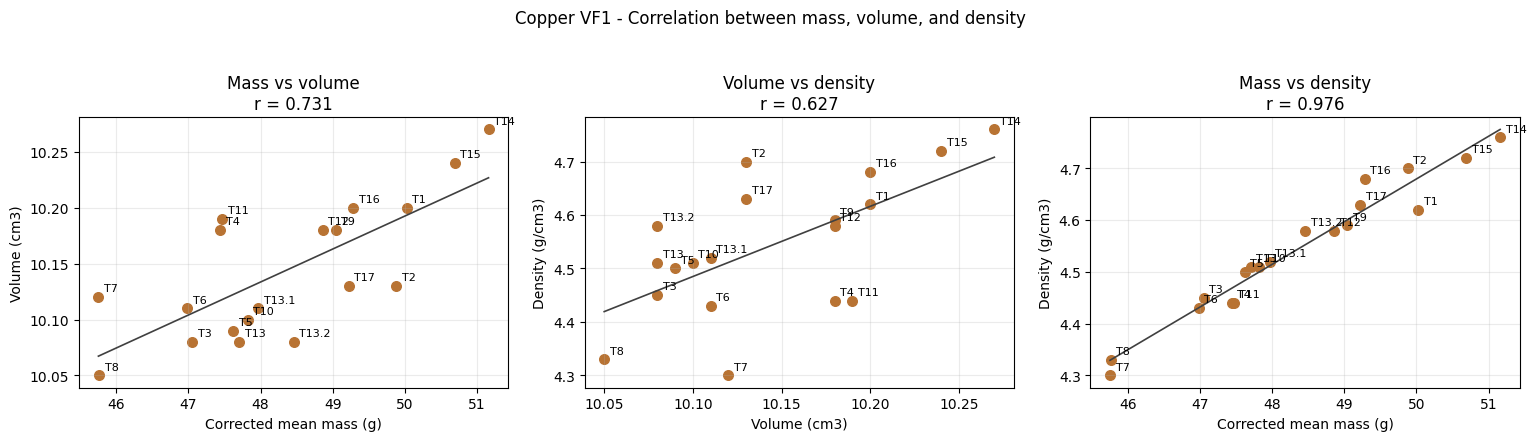

,Run,mass_mean_g,volume_cm3,density_g_cm3
0,T1,50.027,10.20,4.62
1,T2,49.879,10.13,4.70
2,T3,47.049,10.08,4.45
3,T4,47.443,10.18,4.44
4,T5,47.623,10.09,4.50
5,T6,46.984,10.11,4.43
6,T7,45.752,10.12,4.30
7,T8,45.760,10.05,4.33
8,T9,49.043,10.18,4.59
9,T10,47.822,10.10,4.51


,comparison,n,pearson_r
0,Mass vs volume,19,0.731
1,Volume vs density,19,0.627
2,Mass vs density,19,0.976


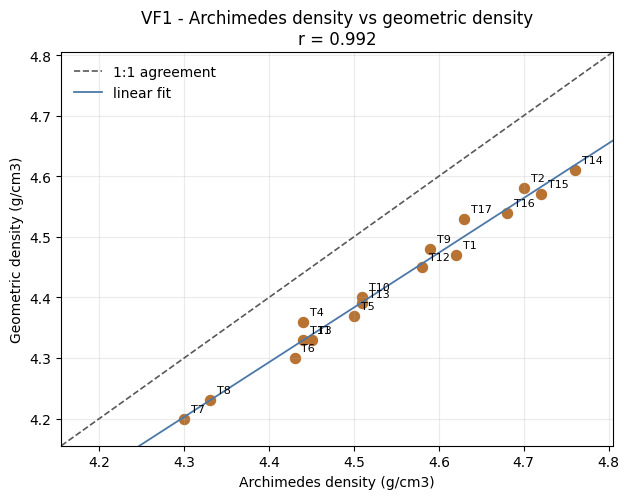

,Run,Archimedes density (g/cm3),Geometrical density (g/cm3)
0,T1,4.62,4.47
1,T2,4.70,4.58
2,T3,4.45,4.33
3,T4,4.44,4.36
4,T5,4.50,4.37
5,T6,4.43,4.30
6,T7,4.30,4.20
7,T8,4.33,4.23
8,T9,4.59,4.48
9,T10,4.51,4.40


,comparison,n,pearson_r,mean_arch_minus_geom_g_cm3,max_abs_difference_g_cm3
0,Archimedes density vs geometric density,17,0.992,0.121,0.15


In [73]:
def offset_corrected_copper_mass(row):
    measurements = pd.to_numeric(
        pd.Series(row["weight_measurements_g"]), errors="coerce"
    ).dropna().astype(float)
    if measurements.empty:
        return pd.to_numeric(row["weight_g"], errors="coerce")
    measurements = measurements.to_numpy(copy=True)
    if (
        len(measurements) >= 2
        and row["Run"] not in MEASUREMENT_OFFSET_EXCLUDED_RUNS
    ):
        measurements[0] += MEASUREMENT_1_OFFSET_G
    return float(measurements.mean())

copper_mass_volume_density = copper_measurements[[
    "Run",
    "weight_measurements_g",
    "weight_g",
    "volume_cm3",
    "density_g_cm3",
]].copy()
copper_mass_volume_density["mass_mean_g"] = (
    copper_mass_volume_density.apply(offset_corrected_copper_mass, axis=1)
)
for column in ["mass_mean_g", "volume_cm3", "density_g_cm3"]:
    copper_mass_volume_density[column] = pd.to_numeric(
        copper_mass_volume_density[column], errors="coerce"
    )
copper_mass_volume_density = copper_mass_volume_density.dropna(
    subset=["mass_mean_g", "volume_cm3", "density_g_cm3"]
)[["Run", "mass_mean_g", "volume_cm3", "density_g_cm3"]]
run_parts = copper_mass_volume_density["Run"].str.extract(
    r"T(\d+)(?:\.(\d+))?"
)
copper_mass_volume_density["_run_order"] = run_parts[0].astype(float)
copper_mass_volume_density["_repeat_order"] = (
    run_parts[1].fillna(0).astype(float)
)
copper_mass_volume_density = (
    copper_mass_volume_density
    .sort_values(["_run_order", "_repeat_order"])
    .drop(columns=["_run_order", "_repeat_order"])
    .reset_index(drop=True)
)

copper_correlation_pairs = [
    ("mass_mean_g", "volume_cm3", "Corrected mean mass (g)", "Volume (cm3)", "Mass vs volume"),
    ("volume_cm3", "density_g_cm3", "Volume (cm3)", "Density (g/cm3)", "Volume vs density"),
    ("mass_mean_g", "density_g_cm3", "Corrected mean mass (g)", "Density (g/cm3)", "Mass vs density"),
]

copper_mass_volume_density_correlation_summary = []
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
for ax, (x_col, y_col, x_label, y_label, title) in zip(axes, copper_correlation_pairs):
    plot_df = copper_mass_volume_density[["Run", x_col, y_col]].dropna()
    r_value = plot_df[x_col].corr(plot_df[y_col])
    copper_mass_volume_density_correlation_summary.append({
        "comparison": title,
        "n": len(plot_df),
        "pearson_r": r_value,
    })

    ax.scatter(plot_df[x_col], plot_df[y_col], color="#b87333", s=48)
    for _, row in plot_df.iterrows():
        ax.annotate(
            row["Run"],
            (row[x_col], row[y_col]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )

    if len(plot_df) >= 2:
        slope, intercept = np.polyfit(plot_df[x_col], plot_df[y_col], 1)
        x_line = np.linspace(plot_df[x_col].min(), plot_df[x_col].max(), 100)
        ax.plot(x_line, slope * x_line + intercept, color="0.25", linewidth=1.2)

    ax.set_title(f"{title}\nr = {r_value:.3f}")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.grid(alpha=0.25)

fig.suptitle("Copper - Correlation between mass, volume, and density", y=1.04)
plt.tight_layout()
plt.show(block=False)

display(copper_mass_volume_density.round({
    "mass_mean_g": 3,
    "volume_cm3": 3,
    "density_g_cm3": 3,
}))
display(pd.DataFrame(
    copper_mass_volume_density_correlation_summary
).round({"pearson_r": 3}))


copper_archimedes_geometric_density = copper_measurements[[
    "Run",
    "density_g_cm3",
    "geometric_density_g_cm3",
]].copy()
for column in [
    "density_g_cm3",
    "geometric_density_g_cm3",
]:
    copper_archimedes_geometric_density[column] = pd.to_numeric(
        copper_archimedes_geometric_density[column],
        errors="coerce",
    )
copper_archimedes_geometric_density = copper_archimedes_geometric_density.dropna(
    subset=["density_g_cm3", "geometric_density_g_cm3"]
).reset_index(drop=True)
run_parts = copper_archimedes_geometric_density["Run"].str.extract(
    r"T(\d+)(?:\.(\d+))?"
)
copper_archimedes_geometric_density["_run_order"] = run_parts[0].astype(float)
copper_archimedes_geometric_density["_repeat_order"] = (
    run_parts[1].fillna(0).astype(float)
)
copper_archimedes_geometric_density = (
    copper_archimedes_geometric_density
    .sort_values(["_run_order", "_repeat_order"])
    .drop(columns=["_run_order", "_repeat_order"])
    .reset_index(drop=True)
)

arch_geom_r = copper_archimedes_geometric_density["density_g_cm3"].corr(
    copper_archimedes_geometric_density["geometric_density_g_cm3"]
)
fig, ax = plt.subplots(figsize=(6.4, 5.1))
ax.scatter(
    copper_archimedes_geometric_density["density_g_cm3"],
    copper_archimedes_geometric_density["geometric_density_g_cm3"],
    color="#b87333",
    s=52,
)
for _, row in copper_archimedes_geometric_density.iterrows():
    ax.annotate(
        row["Run"],
        (row["density_g_cm3"], row["geometric_density_g_cm3"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

min_density = min(
    copper_archimedes_geometric_density["density_g_cm3"].min(),
    copper_archimedes_geometric_density["geometric_density_g_cm3"].min(),
)
max_density = max(
    copper_archimedes_geometric_density["density_g_cm3"].max(),
    copper_archimedes_geometric_density["geometric_density_g_cm3"].max(),
)
padding = max((max_density - min_density) * 0.08, 0.02)
identity = np.linspace(min_density - padding, max_density + padding, 100)
ax.plot(
    identity,
    identity,
    color="0.35",
    linestyle="--",
    linewidth=1.2,
    label="1:1 agreement",
)
if len(copper_archimedes_geometric_density) >= 2:
    slope, intercept = np.polyfit(
        copper_archimedes_geometric_density["density_g_cm3"],
        copper_archimedes_geometric_density["geometric_density_g_cm3"],
        1,
    )
    ax.plot(
        identity,
        slope * identity + intercept,
        color="#4c78a8",
        linewidth=1.3,
        label="linear fit",
    )
ax.set_xlim(min_density - padding, max_density + padding)
ax.set_ylim(min_density - padding, max_density + padding)
ax.set_title(f"Archimedes density vs geometric density\nr = {arch_geom_r:.3f}")
ax.set_xlabel("Archimedes density (g/cm3)")
ax.set_ylabel("Geometric density (g/cm3)")
ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="best")
plt.tight_layout()
plt.show(block=False)

copper_archimedes_geometric_density["density_difference_g_cm3"] = (
    copper_archimedes_geometric_density["density_g_cm3"]
    - copper_archimedes_geometric_density["geometric_density_g_cm3"]
)
density_comparison_display = (
    copper_archimedes_geometric_density[[
        "Run",
        "density_g_cm3",
        "geometric_density_g_cm3",
    ]]
    .rename(columns={
        "density_g_cm3": "Archimedes density (g/cm3)",
        "geometric_density_g_cm3": "Geometrical density (g/cm3)",
    })
)
display(density_comparison_display.round({
    "Archimedes density (g/cm3)": 3,
    "Geometrical density (g/cm3)": 3,
}))
display(pd.DataFrame([{
    "comparison": "Archimedes density vs geometric density",
    "n": len(copper_archimedes_geometric_density),
    "pearson_r": arch_geom_r,
    "mean_arch_minus_geom_g_cm3": copper_archimedes_geometric_density["density_difference_g_cm3"].mean(),
    "max_abs_difference_g_cm3": copper_archimedes_geometric_density["density_difference_g_cm3"].abs().max(),
}]).round({
    "pearson_r": 3,
    "mean_arch_minus_geom_g_cm3": 3,
    "max_abs_difference_g_cm3": 3,
}))


## Mass Analysis: Copper Regression (T1-T17 with T13 Repeats)

This model uses the complete `T1`-`T17` experiment and includes `T13.1` and `T13.2` as separate center-repeat observations.

In [74]:
COPPER_RESPONSE = "weight_g"

COPPER_SELECTED_INTERACTIONS = [
    ("B_flow_ratio", "E_infill_percent"),
    ("B_flow_ratio", "A_layer_height_mm"),
    ("C_nozzle_temp_C", "D_speed_mm_s"),
    ("B_flow_ratio", "D_speed_mm_s"),
    ("A_layer_height_mm", "C_nozzle_temp_C"),
]

COPPER_CONTOUR_PAIRS = [
    ("B_flow_ratio", "A_layer_height_mm"),
    ("B_flow_ratio", "E_infill_percent"),
    ("B_flow_ratio", "D_speed_mm_s"),
    ("A_layer_height_mm", "C_nozzle_temp_C"),
    ("A_layer_height_mm", "E_infill_percent"),
    ("A_layer_height_mm", "D_speed_mm_s"),
    ("B_flow_ratio", "C_nozzle_temp_C"),
    ("C_nozzle_temp_C", "D_speed_mm_s"),
    ("D_speed_mm_s", "E_infill_percent"),
]

planned_coded_response_table = copper_dsd_coded.merge(
    copper_measurements[["Run", *response_cols]],
    on="Run",
    how="left",
)


def code_extra_copper_runs(extra_measurements):
    extra_coded_rows = []
    for _, row in extra_measurements.iterrows():
        coded_row = {"Run": row["Run"]}
        has_all_factor_settings = True
        for factor in copper_factor_names:
            real_value = row.get(factor)
            if pd.isna(real_value):
                has_all_factor_settings = False
                break
            real_to_coded = {
                real_level: coded_level
                for coded_level, real_level in copper_factor_levels[factor].items()
            }
            if real_value not in real_to_coded:
                raise ValueError(
                    f"{row['Run']} has {factor}={real_value}, "
                    "which is not one of the configured levels."
                )
            coded_row[factor] = real_to_coded[real_value]
        if has_all_factor_settings:
            for column in copper_measurements.columns:
                if column != "Run" and column not in coded_row:
                    coded_row[column] = row[column]
            extra_coded_rows.append(coded_row)
    return pd.DataFrame(extra_coded_rows)


extra_copper_measurements = copper_measurements[
    ~copper_measurements["Run"].isin(copper_dsd_coded["Run"])
].copy()
extra_coded_response_table = code_extra_copper_runs(extra_copper_measurements)

# Use the complete T1-T17 experiment, including the available T13 center repeats.
augmented_run_labels = [
    *[f"T{i}" for i in range(1, 18)],
    "T13.1",
    "T13.2",
]
augmented_extra_table = extra_coded_response_table[
    extra_coded_response_table["Run"].isin(augmented_run_labels)
].copy()
copper_augmented_response_table = pd.concat(
    [planned_coded_response_table, augmented_extra_table],
    ignore_index=True,
)
run_parts = copper_augmented_response_table["Run"].str.extract(
    r"T(\d+)(?:\.(\d+))?"
)
copper_augmented_response_table["run_order"] = run_parts[0].astype(float)
copper_augmented_response_table["repeat_order"] = run_parts[1].fillna(0).astype(float)
copper_augmented_response_table = (
    copper_augmented_response_table
    .sort_values(["run_order", "repeat_order"])
    .drop(columns=["run_order", "repeat_order"])
    .reset_index(drop=True)
)
augmented_measured_count = copper_augmented_response_table[COPPER_RESPONSE].notna().sum()

main_effect_terms = default_dsd_terms(copper_factor_names)
quadratic_terms = default_dsd_terms(copper_factor_names, include_quadratic=True)
copper_augmented_model_terms = (
    quadratic_terms
    if augmented_measured_count >= len(quadratic_terms) + 1
    else main_effect_terms
)

print(f"Response: {response_label(COPPER_RESPONSE)}")
print(
    f"T1-T17 measured runs: "
    f"{augmented_measured_count}/{len(copper_augmented_response_table)}"
)
print("T1-T17 model terms:", copper_augmented_model_terms)
display(
    copper_augmented_response_table[
        ["Run", *copper_factor_names, COPPER_RESPONSE, "notes"]
    ].rename(columns={COPPER_RESPONSE: "Mass (g)"})
)


Response: Mass (g)
T1-T17 measured runs: 19/19
T1-T17 model terms: ['A_layer_height_mm', 'B_flow_ratio', 'C_nozzle_temp_C', 'D_speed_mm_s', 'E_infill_percent', 'A_layer_height_mm^2', 'B_flow_ratio^2', 'C_nozzle_temp_C^2', 'D_speed_mm_s^2', 'E_infill_percent^2']


,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,Mass (g),notes
0,T1,1,1,1,1,1,48.7610,many blobs.
1,T2,0,1,-1,-1,1,48.6130,still many blobs which fall off. Prime tower s...
2,T3,1,0,1,-1,-1,45.7835,"less material adhering to nozzle, line missing..."
3,T4,-1,1,0,1,-1,46.1770,"again more clumping, but not excessive"
4,T5,-1,-1,1,0,1,46.3570,
5,T6,1,-1,-1,1,0,45.7175,less stuff on nozzle.
6,T7,-1,-1,-1,-1,-1,44.4865,looks surprisingly good but holes between infi...
7,T8,0,-1,1,1,-1,44.4940,wieder mehr an der nozzle. Viel zwischenwand u...
8,T9,-1,0,-1,1,1,47.7765,
9,T10,1,-1,0,-1,1,46.5555,


,term,coefficient,standard_error,standardized_effect,t_value,F_value,p_value,absolute_standardized_effect,absolute_coefficient
0,Intercept,47.1953,0.3738,126.2619,126.2619,15942.0754,0.0000,126.2619,47.1953
1,A_layer_height_mm,0.1107,0.1994,0.5551,0.5551,0.3081,0.5940,0.5551,0.1107
2,B_flow_ratio,1.0725,0.1973,5.4345,5.4345,29.5340,0.0006,5.4345,1.0725
3,C_nozzle_temp_C,0.0551,0.1994,0.2764,0.2764,0.0764,0.7892,0.2764,0.0551
4,D_speed_mm_s,-0.1096,0.1973,-0.5555,-0.5555,0.3086,0.5937,0.5555,0.1096
5,E_infill_percent,1.1909,0.1973,6.0347,6.0347,36.4180,0.0003,6.0347,1.1909
6,A_layer_height_mm^2,-0.3018,0.3572,-0.8450,-0.8450,0.7141,0.4226,0.8450,0.3018
7,B_flow_ratio^2,-0.2753,0.4219,-0.6527,-0.6527,0.4260,0.5323,0.6527,0.2753
8,C_nozzle_temp_C^2,-0.1787,0.3572,-0.5001,-0.5001,0.2501,0.6304,0.5001,0.1787
9,D_speed_mm_s^2,0.2259,0.4219,0.5355,0.5355,0.2867,0.6069,0.5355,0.2259


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,10,46.4243,4.6424,10.4614,0.0014
1,Residual,8,3.5502,0.4438,NaN,NaN
2,Total,18,49.9744,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value
1,A_layer_height_mm,0.1107,0.1994,0.5551,0.3081,0.5940
2,B_flow_ratio,1.0725,0.1973,5.4345,29.5340,0.0006
3,C_nozzle_temp_C,0.0551,0.1994,0.2764,0.0764,0.7892
4,D_speed_mm_s,-0.1096,0.1973,-0.5555,0.3086,0.5937
5,E_infill_percent,1.1909,0.1973,6.0347,36.4180,0.0003
6,A_layer_height_mm^2,-0.3018,0.3572,-0.8450,0.7141,0.4226
7,B_flow_ratio^2,-0.2753,0.4219,-0.6527,0.4260,0.5323
8,C_nozzle_temp_C^2,-0.1787,0.3572,-0.5001,0.2501,0.6304
9,D_speed_mm_s^2,0.2259,0.4219,0.5355,0.2867,0.6069
10,E_infill_percent^2,-0.1521,0.4219,-0.3605,0.1300,0.7278


Partial term-wise ANOVA (Type III-style tests)


,source,df,sum_sq,mean_sq,F_value,p_value
0,A_layer_height_mm,1,0.1367,0.1367,0.3081,0.5940
1,B_flow_ratio,1,13.1063,13.1063,29.5340,0.0006
2,C_nozzle_temp_C,1,0.0339,0.0339,0.0764,0.7892
3,D_speed_mm_s,1,0.1369,0.1369,0.3086,0.5937
4,E_infill_percent,1,16.1612,16.1612,36.4180,0.0003
5,A_layer_height_mm^2,1,0.3169,0.3169,0.7141,0.4226
6,B_flow_ratio^2,1,0.1890,0.1890,0.4260,0.5323
7,C_nozzle_temp_C^2,1,0.1110,0.1110,0.2501,0.6304
8,D_speed_mm_s^2,1,0.1272,0.1272,0.2867,0.6069
9,E_infill_percent^2,1,0.0577,0.0577,0.1300,0.7278


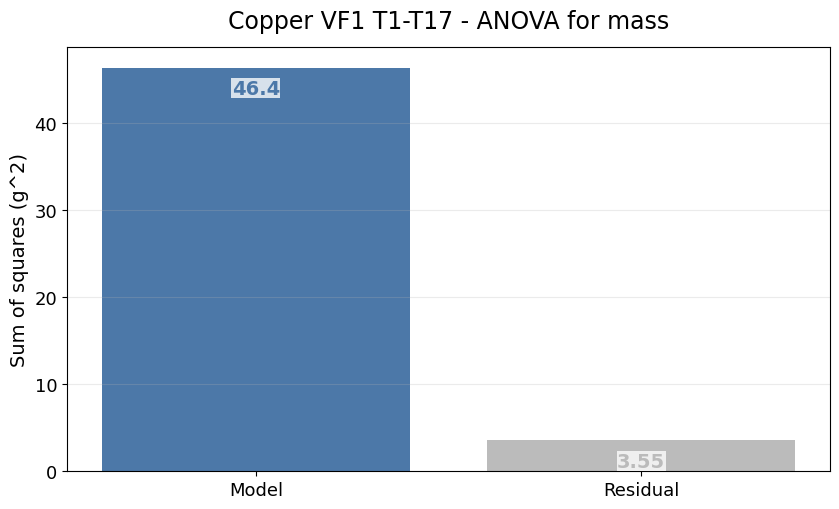

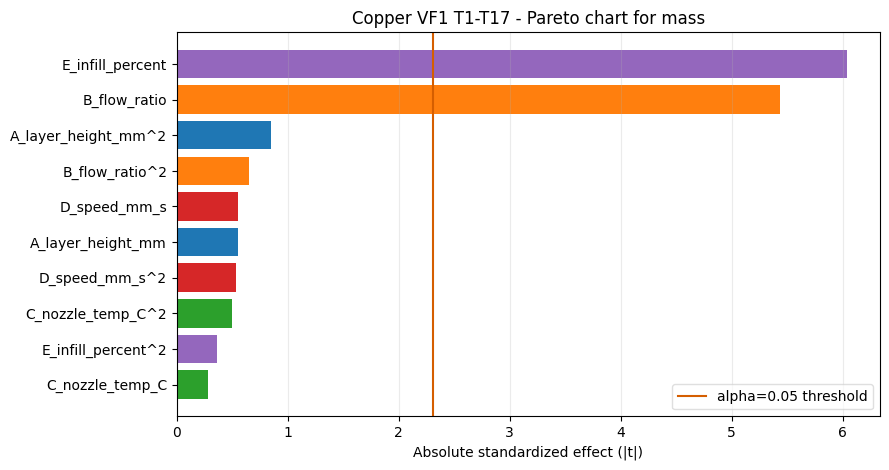

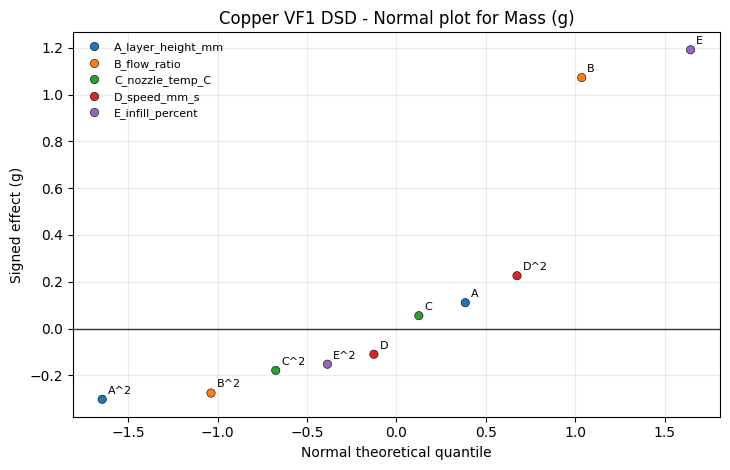

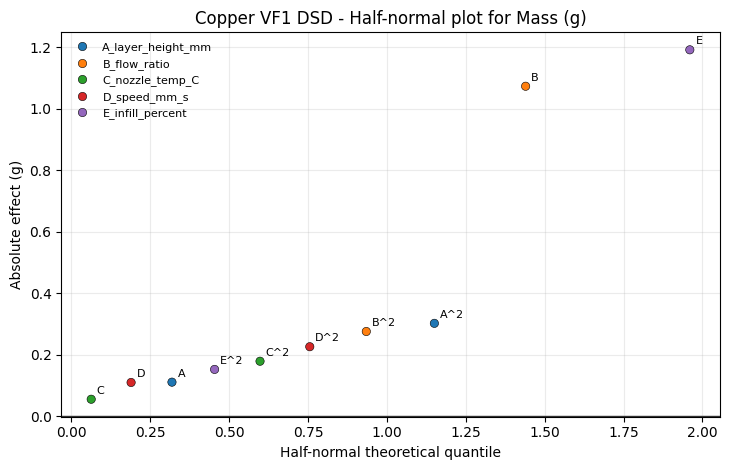

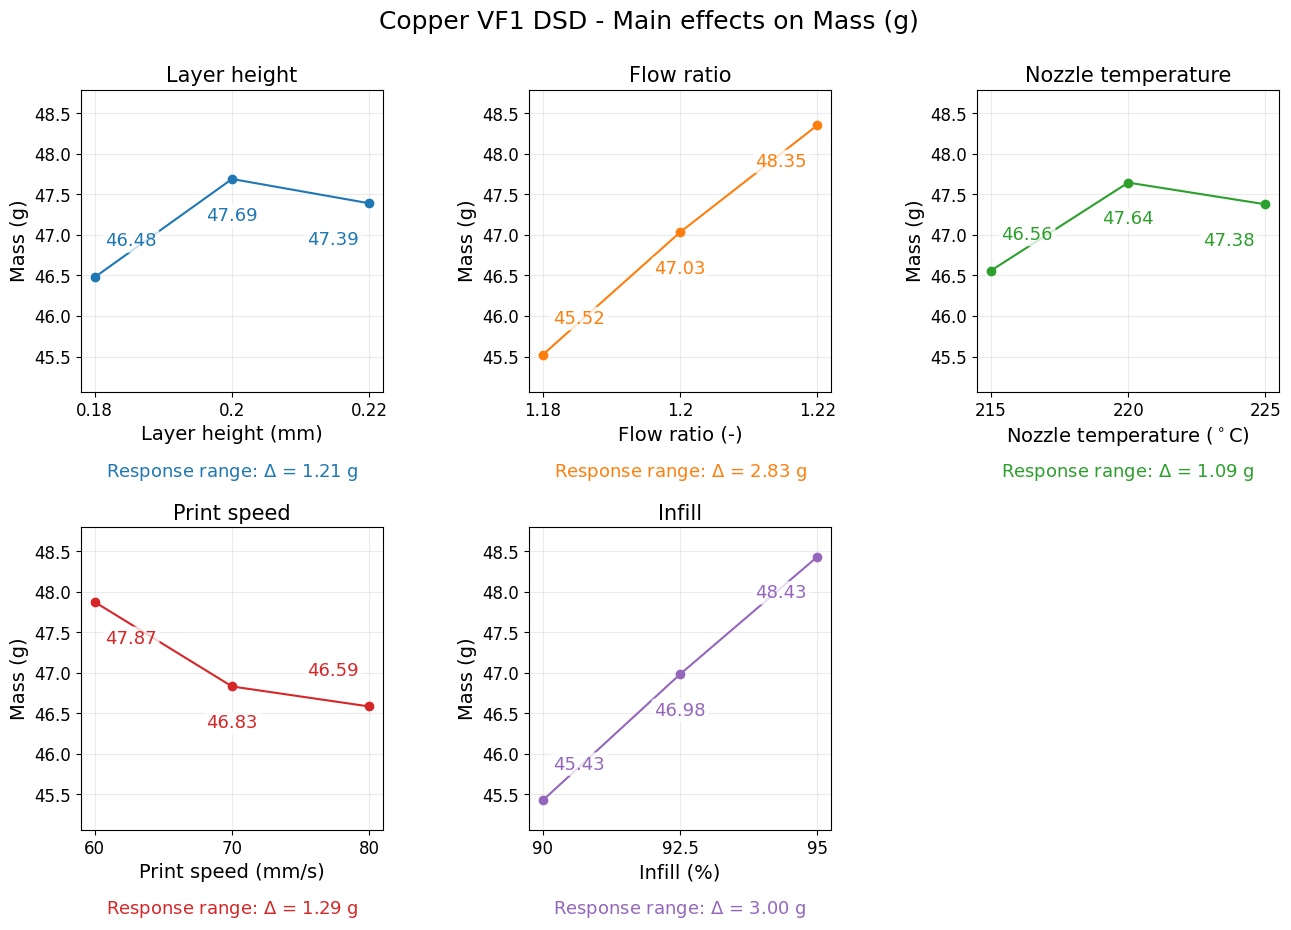

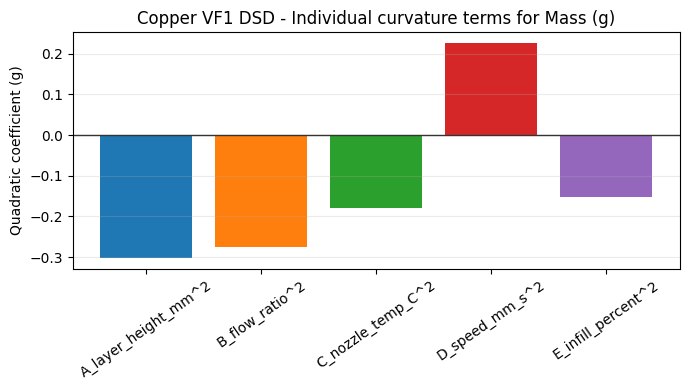

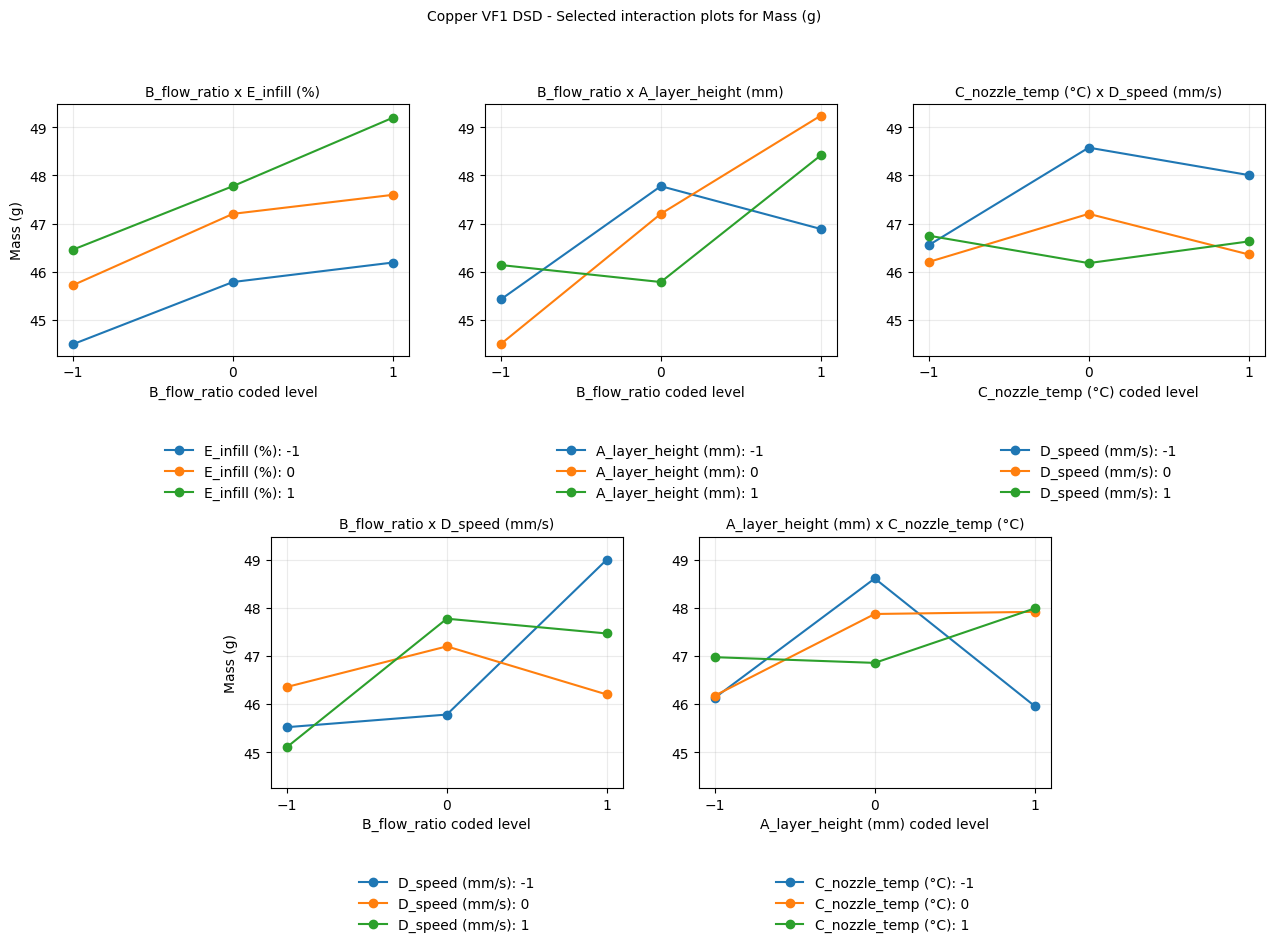

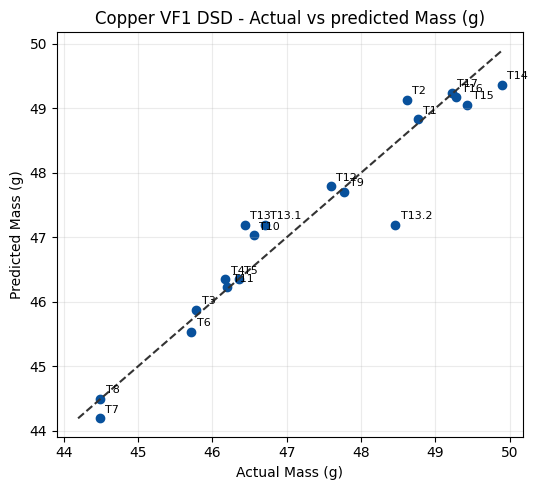

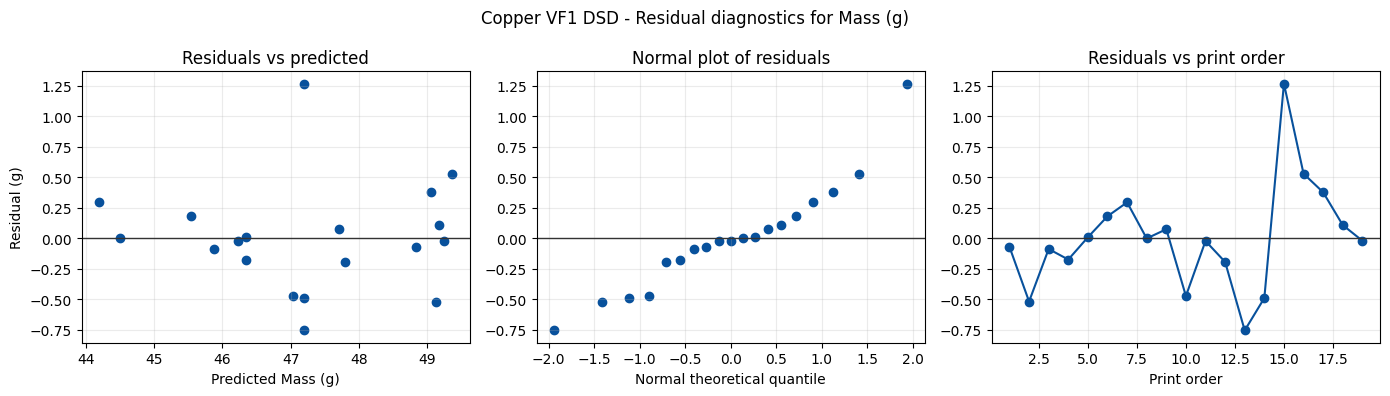

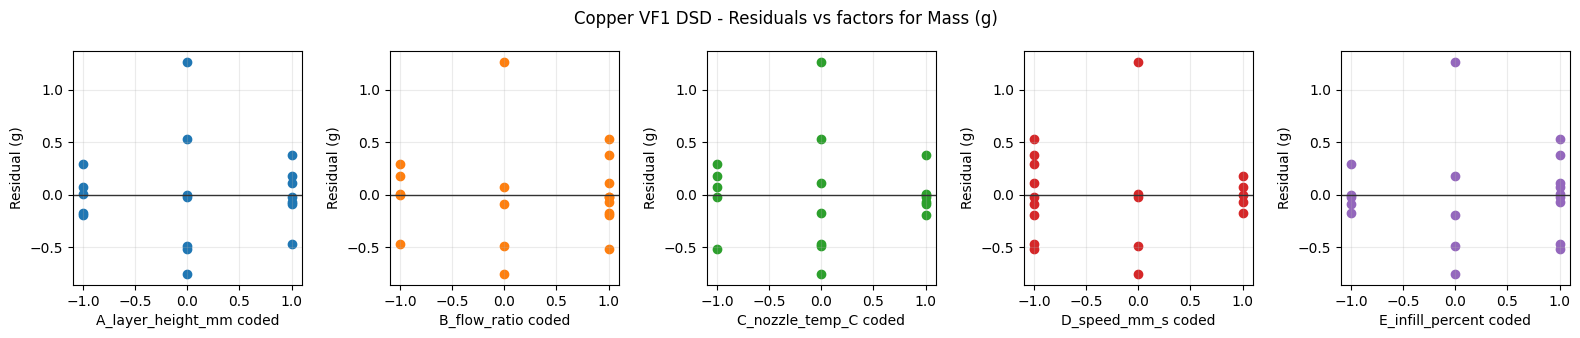

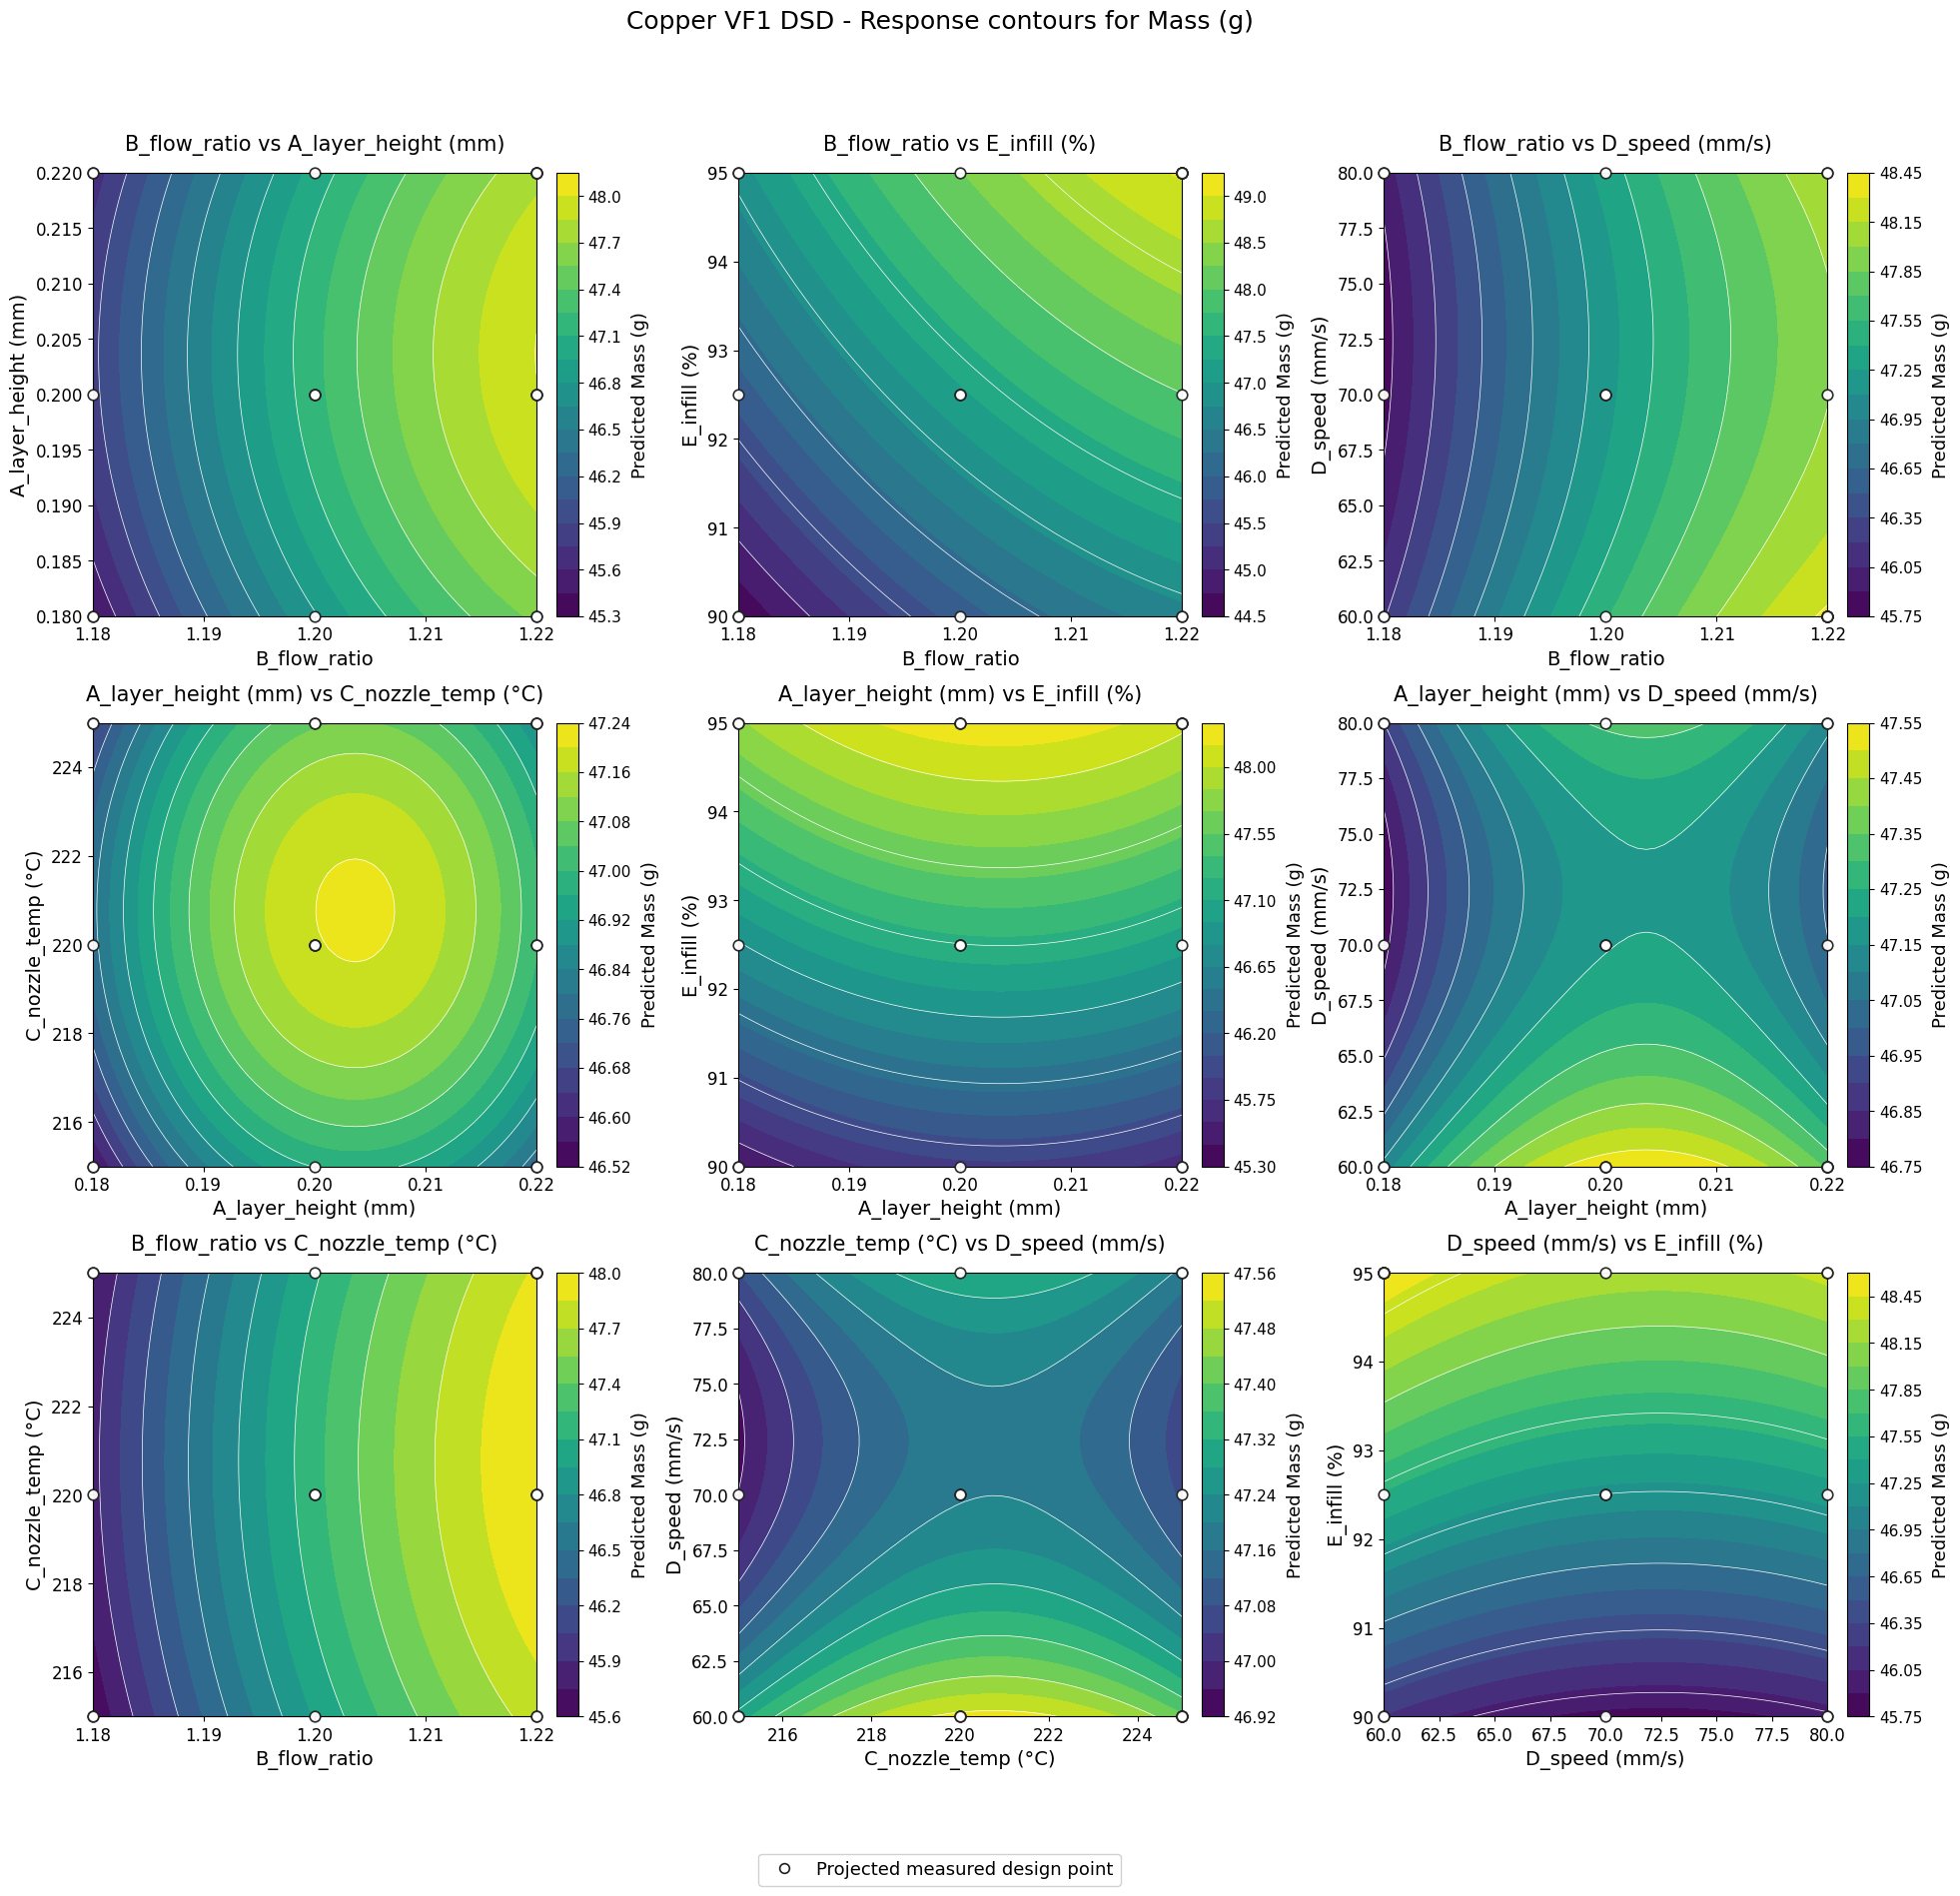

In [75]:
if augmented_measured_count >= len(copper_augmented_model_terms) + 1:
    copper_augmented_response_model = fit_copper_response_model(
        copper_augmented_response_table,
        response=COPPER_RESPONSE,
        terms=copper_augmented_model_terms,
    )
    display(copper_augmented_response_model["coefficient_df"].round(4))
    copper_augmented_anova_table = build_copper_anova_table(copper_augmented_response_model)
    display(copper_augmented_anova_table.round(4))
    display(build_copper_term_significance_table(copper_augmented_response_model).round(4))
    copper_augmented_term_anova_table = build_copper_term_anova_table(
        copper_augmented_response_model
    )
    print("Partial term-wise ANOVA (Type III-style tests)")
    display(copper_augmented_term_anova_table.round(4))
    plot_copper_anova(
        copper_augmented_anova_table,
        response=COPPER_RESPONSE,
        title="Copper T1-T17 - ANOVA for mass",
    )

    plot_copper_pareto(
        copper_augmented_response_model,
        title="Copper T1-T17 - Pareto chart for mass",
        alpha=SIGNIFICANCE_ALPHA,
    )
    plot_copper_normal_effects(copper_augmented_response_model, half_normal=False)
    plot_copper_normal_effects(copper_augmented_response_model, half_normal=True)

    plot_copper_main_effects(
        copper_augmented_response_table,
        copper_factor_levels,
        response=COPPER_RESPONSE,
        factor_names=copper_factor_names,
        max_columns=3,
    )

    if copper_augmented_model_terms == quadratic_terms:
        plot_copper_curvature(copper_augmented_response_model)

    plot_copper_interactions(
        copper_augmented_response_table,
        response=COPPER_RESPONSE,
        interaction_pairs=COPPER_SELECTED_INTERACTIONS,
    )
    plot_copper_actual_vs_predicted(copper_augmented_response_model)
    plot_copper_residuals(copper_augmented_response_model, copper_factor_names)
    plot_copper_contours(
        copper_augmented_response_model,
        levels=copper_factor_levels,
        factor_pairs=COPPER_CONTOUR_PAIRS,
        fixed_level=0,
    )
else:
    copper_augmented_response_model = None
    print("Not enough measured runs yet for the T1-T17 model with T13 repeats.")


## Average-Density Analysis: T1-T17

This regression uses `avg_density_g_cm3`, the average of Archimedes and geometrical density, for `T1`-`T17`. The additional center specimens `T13.1` and `T13.2` are excluded because geometrical density has not been measured for them, so an average cannot be calculated.


Response: avg_density_g_cm3 (Average density (g/cm3))
T1-T17 density runs: 17/19
T1-T17 density model terms: ['A_layer_height_mm', 'B_flow_ratio', 'C_nozzle_temp_C', 'D_speed_mm_s', 'E_infill_percent', 'A_layer_height_mm^2', 'B_flow_ratio^2', 'C_nozzle_temp_C^2', 'D_speed_mm_s^2', 'E_infill_percent^2']


,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,density_g_cm3,geometric_density_g_cm3,avg_density_g_cm3,notes
0,T1,1,1,1,1,1,4.62,4.47,4.54,many blobs.
1,T2,0,1,-1,-1,1,4.70,4.58,4.64,still many blobs which fall off. Prime tower s...
2,T3,1,0,1,-1,-1,4.45,4.33,4.39,"less material adhering to nozzle, line missing..."
3,T4,-1,1,0,1,-1,4.44,4.36,4.40,"again more clumping, but not excessive"
4,T5,-1,-1,1,0,1,4.50,4.37,4.44,
5,T6,1,-1,-1,1,0,4.43,4.30,4.37,less stuff on nozzle.
6,T7,-1,-1,-1,-1,-1,4.30,4.20,4.25,looks surprisingly good but holes between infi...
7,T8,0,-1,1,1,-1,4.33,4.23,4.28,wieder mehr an der nozzle. Viel zwischenwand u...
8,T9,-1,0,-1,1,1,4.59,4.48,4.54,
9,T10,1,-1,0,-1,1,4.51,4.40,4.46,


,term,coefficient,standard_error,standardized_effect,t_value,F_value,p_value,absolute_standardized_effect,absolute_coefficient
0,Intercept,4.46765,0.03561,125.46166,125.46166,15740.62790,0.00000,125.46166,4.46765
1,A_layer_height_mm,0.00267,0.01157,0.23058,0.23058,0.05317,0.82530,0.23058,0.00267
2,B_flow_ratio,0.06936,0.01144,6.06213,6.06213,36.74944,0.00091,6.06213,0.06936
3,C_nozzle_temp_C,-0.00296,0.01157,-0.25566,-0.25566,0.06536,0.80675,0.25566,0.00296
4,D_speed_mm_s,-0.01436,0.01144,-1.25484,-1.25484,1.57462,0.25620,1.25484,0.01436
5,E_infill_percent,0.09436,0.01144,8.24727,8.24727,68.01739,0.00017,8.24727,0.09436
6,A_layer_height_mm^2,-0.02256,0.02134,-1.05695,-1.05695,1.11715,0.33122,1.05695,0.02256
7,B_flow_ratio^2,-0.02911,0.02564,-1.13530,-1.13530,1.28892,0.29956,1.13530,0.02911
8,C_nozzle_temp_C^2,-0.01068,0.02134,-0.50058,-0.50058,0.25058,0.63449,0.50058,0.01068
9,D_speed_mm_s^2,0.02589,0.02564,1.00943,1.00943,1.01896,0.35173,1.00943,0.02589


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,10,0.24965,0.02497,16.73882,0.00131
1,Residual,6,0.00895,0.00149,NaN,NaN
2,Total,16,0.25860,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value
1,A_layer_height_mm,0.00267,0.01157,0.23058,0.05317,0.82530
2,B_flow_ratio,0.06936,0.01144,6.06213,36.74944,0.00091
3,C_nozzle_temp_C,-0.00296,0.01157,-0.25566,0.06536,0.80675
4,D_speed_mm_s,-0.01436,0.01144,-1.25484,1.57462,0.25620
5,E_infill_percent,0.09436,0.01144,8.24727,68.01739,0.00017
6,A_layer_height_mm^2,-0.02256,0.02134,-1.05695,1.11715,0.33122
7,B_flow_ratio^2,-0.02911,0.02564,-1.13530,1.28892,0.29956
8,C_nozzle_temp_C^2,-0.01068,0.02134,-0.50058,0.25058,0.63449
9,D_speed_mm_s^2,0.02589,0.02564,1.00943,1.01896,0.35173
10,E_infill_percent^2,-0.00411,0.02564,-0.16042,0.02574,0.87781


Partial term-wise ANOVA (Type III-style tests)


,source,df,sum_sq,mean_sq,F_value,p_value
0,A_layer_height_mm,1,0.00008,0.00008,0.05317,0.82530
1,B_flow_ratio,1,0.05481,0.05481,36.74944,0.00091
2,C_nozzle_temp_C,1,0.00010,0.00010,0.06536,0.80675
3,D_speed_mm_s,1,0.00235,0.00235,1.57462,0.25620
4,E_infill_percent,1,0.10144,0.10144,68.01739,0.00017
5,A_layer_height_mm^2,1,0.00167,0.00167,1.11715,0.33122
6,B_flow_ratio^2,1,0.00192,0.00192,1.28892,0.29956
7,C_nozzle_temp_C^2,1,0.00037,0.00037,0.25058,0.63449
8,D_speed_mm_s^2,1,0.00152,0.00152,1.01896,0.35173
9,E_infill_percent^2,1,0.00004,0.00004,0.02574,0.87781


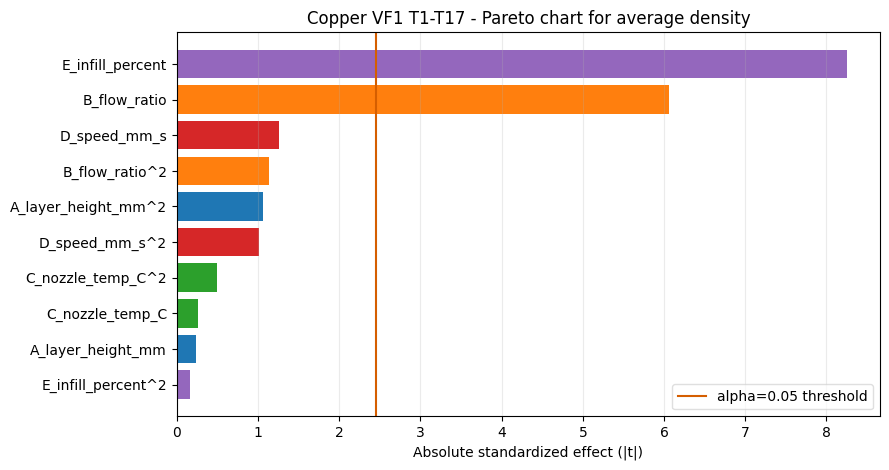

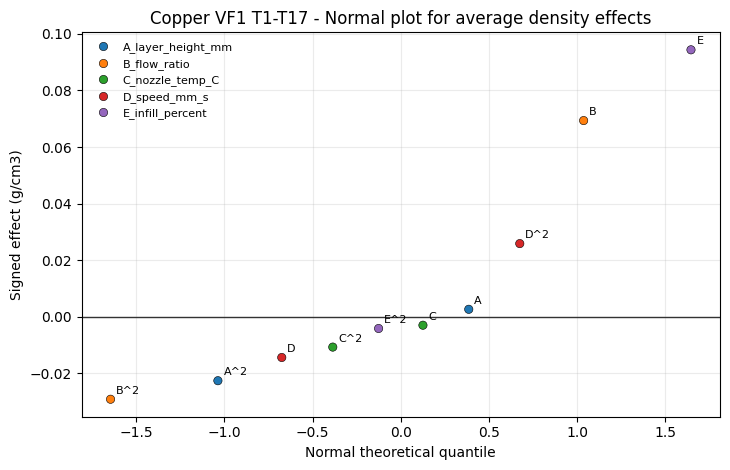

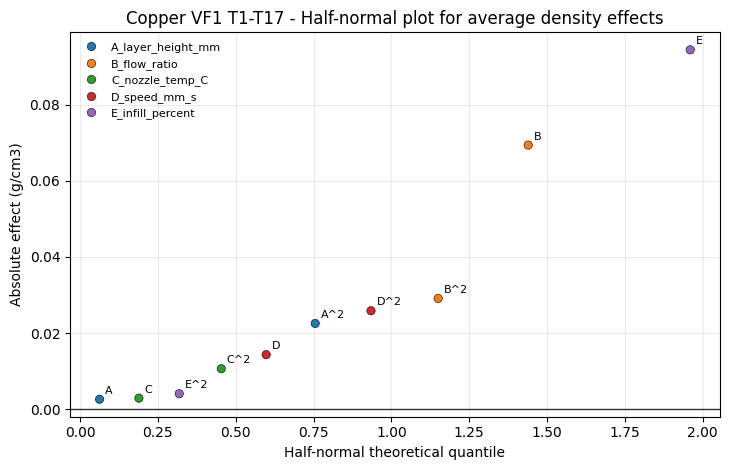

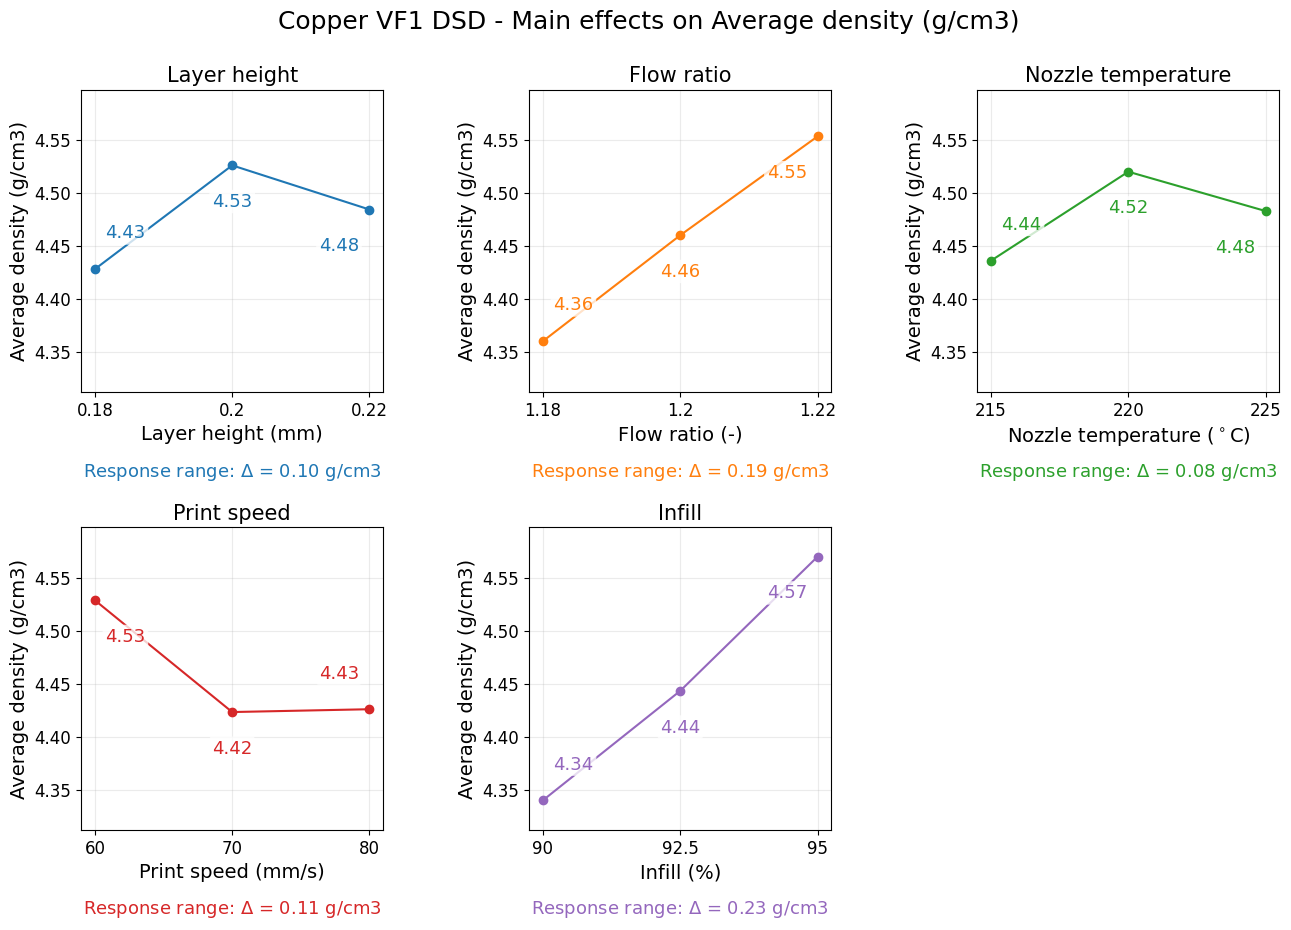

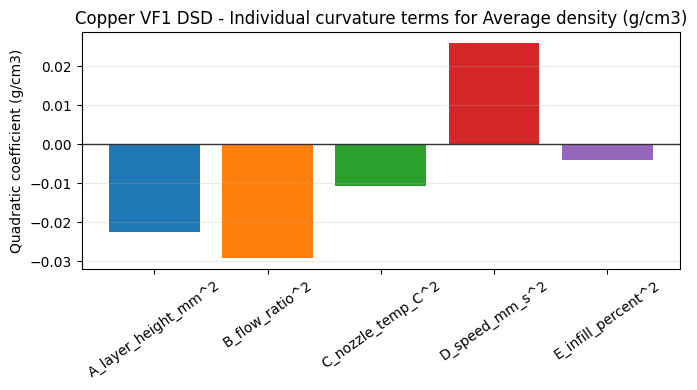

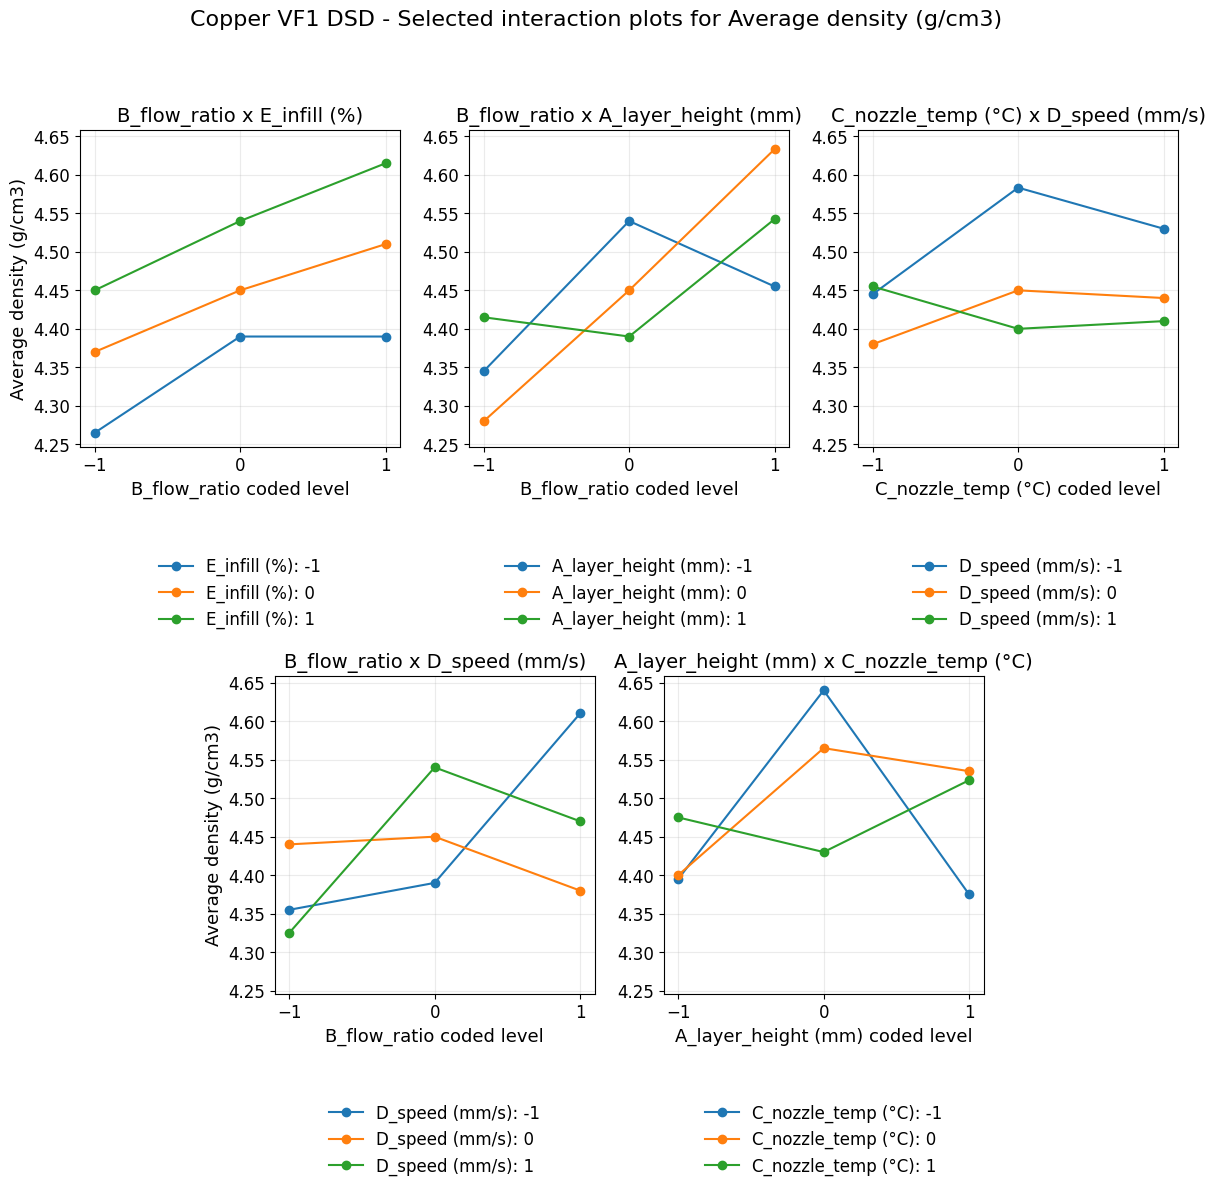

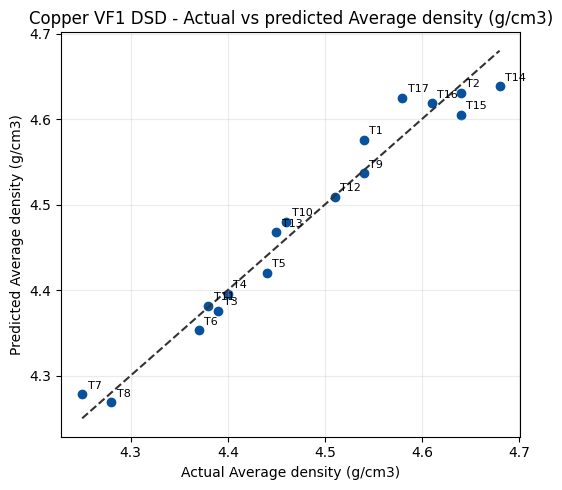

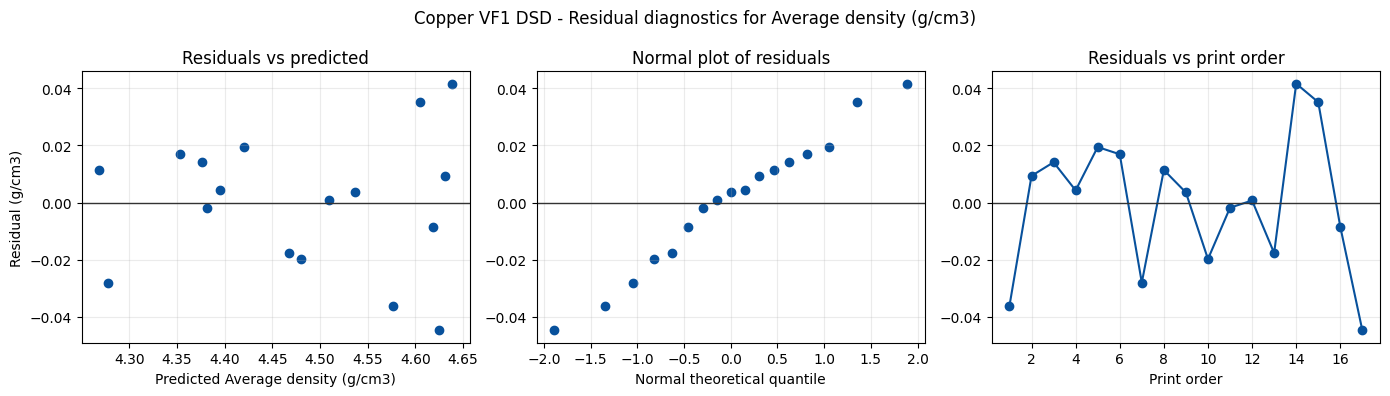

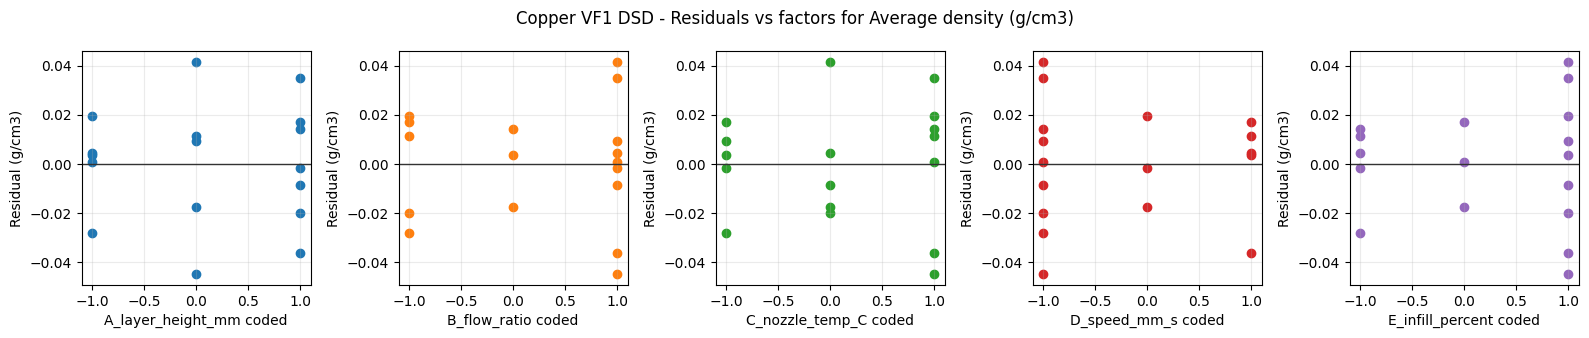

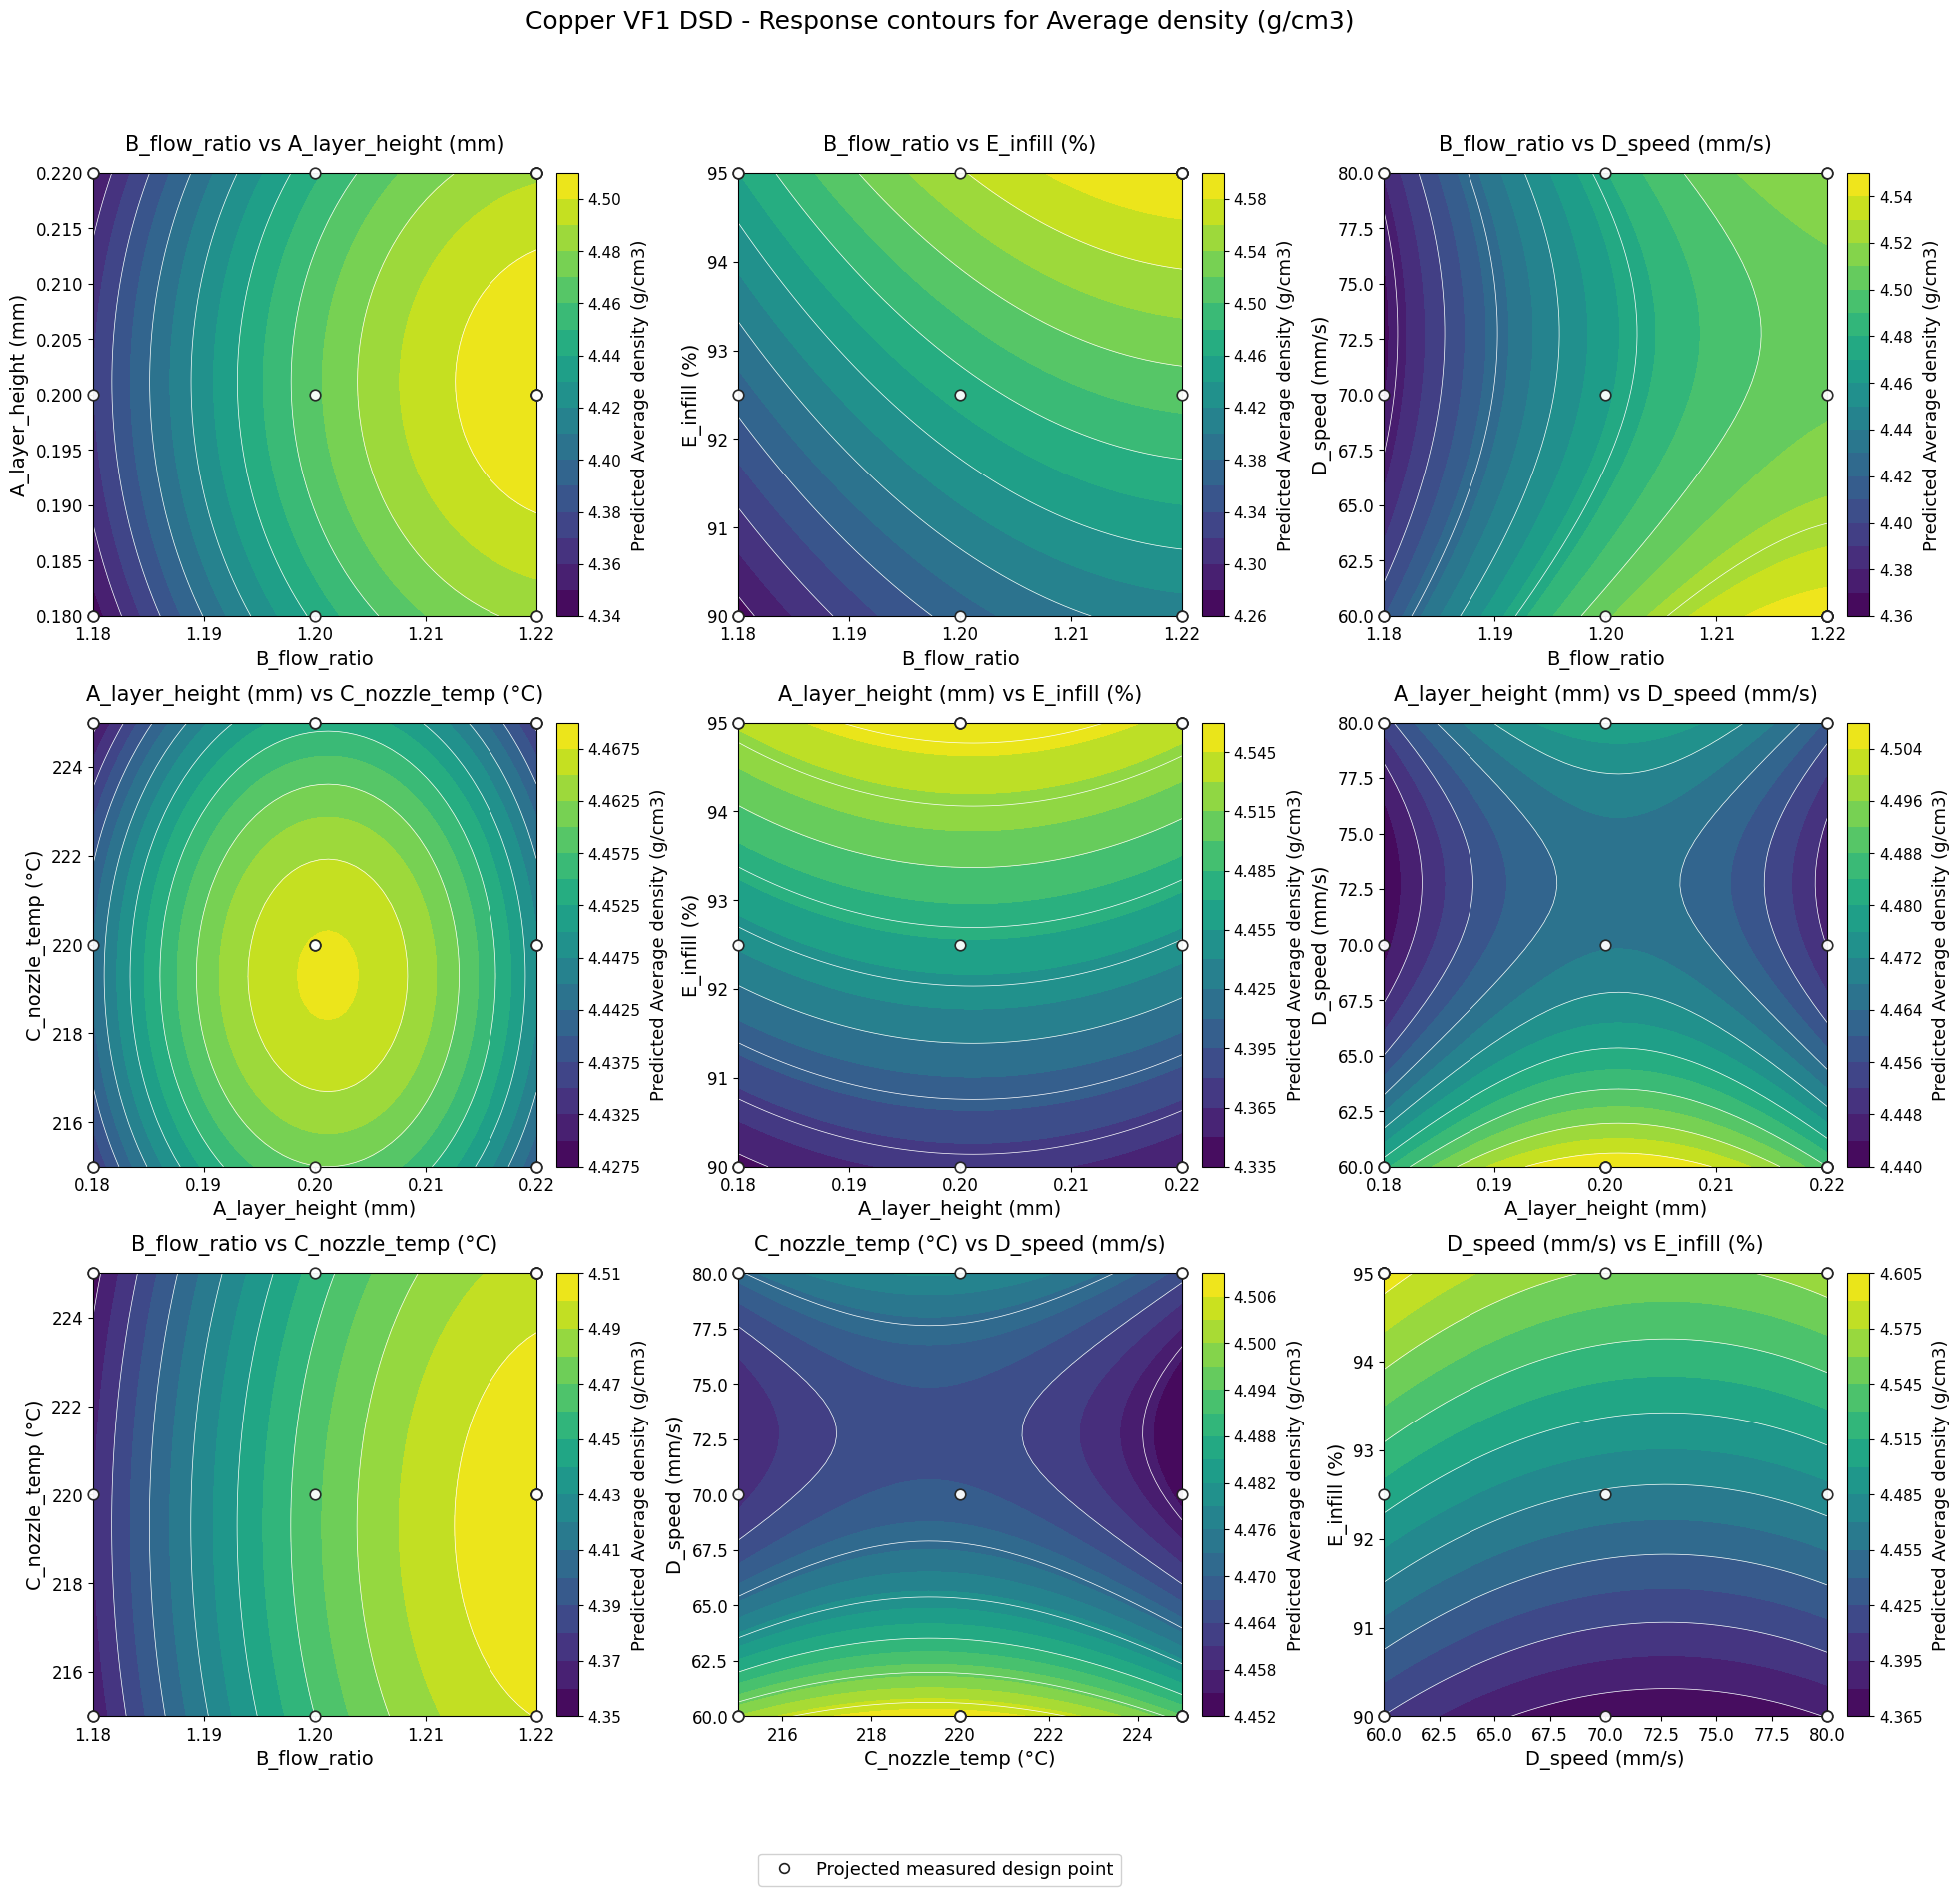

In [76]:
COPPER_DENSITY_RESPONSE = "avg_density_g_cm3"

augmented_density_measured_count = copper_augmented_response_table[COPPER_DENSITY_RESPONSE].notna().sum()
if augmented_density_measured_count >= len(quadratic_terms) + 1:
    copper_augmented_density_model_terms = quadratic_terms
else:
    copper_augmented_density_model_terms = main_effect_terms

print(f"Response: {COPPER_DENSITY_RESPONSE} ({response_label(COPPER_DENSITY_RESPONSE)})")
print(
    f"T1-T17 density runs: {augmented_density_measured_count}/{len(copper_augmented_response_table)}"
)
print("T1-T17 density model terms:", copper_augmented_density_model_terms)
display(copper_augmented_response_table[[
    "Run",
    *copper_factor_names,
    "density_g_cm3",
    "geometric_density_g_cm3",
    COPPER_DENSITY_RESPONSE,
    "notes",
]])

if augmented_density_measured_count >= len(copper_augmented_density_model_terms) + 1:
    copper_augmented_density_response_model = fit_copper_response_model(
        copper_augmented_response_table,
        response=COPPER_DENSITY_RESPONSE,
        terms=copper_augmented_density_model_terms,
    )
    display(copper_augmented_density_response_model["coefficient_df"].round(5))
    copper_augmented_density_anova_table = build_copper_anova_table(
        copper_augmented_density_response_model
    )
    display(copper_augmented_density_anova_table.round(5))
    display(build_copper_term_significance_table(copper_augmented_density_response_model).round(5))
    copper_augmented_density_term_anova_table = build_copper_term_anova_table(
        copper_augmented_density_response_model
    )
    print("Partial term-wise ANOVA (Type III-style tests)")
    display(copper_augmented_density_term_anova_table.round(5))
    plot_copper_pareto(
        copper_augmented_density_response_model,
        title="Copper T1-T17 - Pareto chart for average density",
        alpha=SIGNIFICANCE_ALPHA,
    )
    plot_copper_normal_effects(
        copper_augmented_density_response_model,
        half_normal=False,
        title="Copper T1-T17 - Normal plot for average density effects",
    )
    plot_copper_normal_effects(
        copper_augmented_density_response_model,
        half_normal=True,
        title="Copper T1-T17 - Half-normal plot for average density effects",
    )
    plot_copper_main_effects(
        copper_augmented_response_table,
        copper_factor_levels,
        response=COPPER_DENSITY_RESPONSE,
        factor_names=copper_factor_names,
        max_columns=3,
    )
    if copper_augmented_density_model_terms == quadratic_terms:
        plot_copper_curvature(copper_augmented_density_response_model)
    plot_copper_interactions(
        copper_augmented_response_table,
        response=COPPER_DENSITY_RESPONSE,
        interaction_pairs=COPPER_SELECTED_INTERACTIONS,
        figsize=(12, 12),
        font_size=13,
    )
    plot_copper_actual_vs_predicted(copper_augmented_density_response_model)
    plot_copper_residuals(copper_augmented_density_response_model, copper_factor_names)
    plot_copper_contours(
        copper_augmented_density_response_model,
        levels=copper_factor_levels,
        factor_pairs=COPPER_CONTOUR_PAIRS,
        fixed_level=0,
    )
else:
    copper_augmented_density_response_model = None
    print("Not enough density measurements yet for the T1-T17 density model terms.")


### ANOVA: Explained versus Residual Density Variation

Percentages are calculated from the model and residual sums of squares for the augmented T1-T17 average-density model.


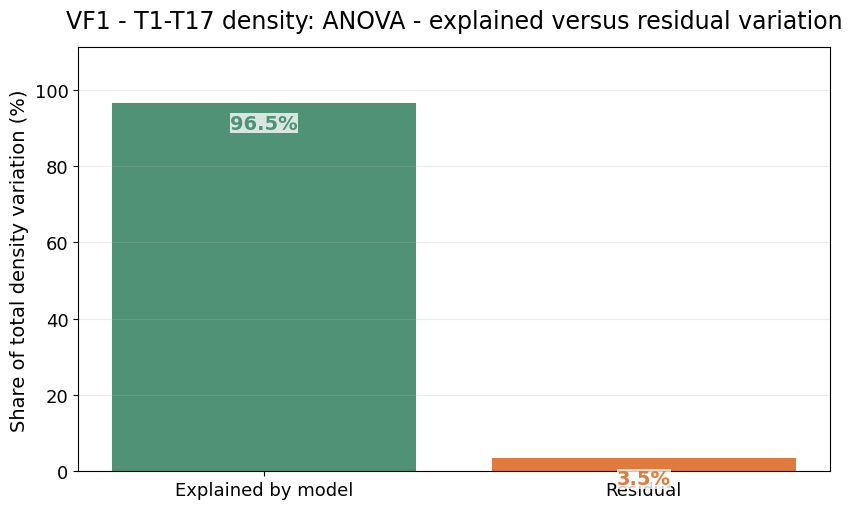

In [77]:
if copper_augmented_density_response_model is not None:
    plot_copper_anova(
        copper_augmented_density_anova_table,
        response=COPPER_DENSITY_RESPONSE,
        title="T1-T17 density: ANOVA - explained versus residual variation",
        variation_percent=True,
    )


## Multiresponse Desirability

c:\Users\sarklug\AppData\Local\Programs\Python\Python314\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,Run,density_g_cm3,porosity_percent,log_leakage_rate,visible_clumping_score,overall_desirability
0,T1,4.62,4.60,None,None,0.821868
1,T2,4.70,2.98,None,None,0.923015
2,T3,4.45,8.16,None,None,0.602629
3,T4,4.44,8.25,None,None,0.593829
4,T5,4.50,7.08,None,None,0.668315
5,T6,4.43,8.56,None,None,0.577432
6,T7,4.30,11.10,None,None,0.415441
7,T8,4.33,10.52,None,None,0.452663
8,T9,4.59,5.11,None,None,0.787190
9,T10,4.51,6.77,None,None,0.684630


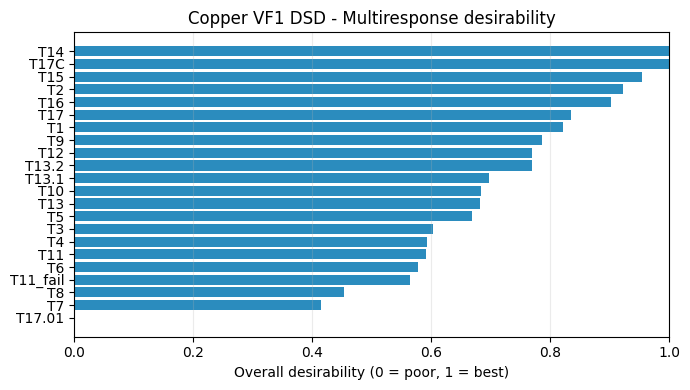

In [78]:
copper_desirability_table = build_copper_desirability_table(copper_measurement_table)
display(copper_desirability_table[[
    "Run",
    "density_g_cm3",
    "porosity_percent",
    "log_leakage_rate",
    "visible_clumping_score",
    "overall_desirability",
]])
plot_copper_desirability(copper_desirability_table)

## VF1 Sintered Analysis

### T17 Green-to-Sintered Follow-up

`T17` is treated as the green reference specimen. `T17.01` is the first sintered follow-up of the same parameter setting and remains part of the sintered comparison even though it has no DoE factor settings. Future sintered rows can be added by setting `specimen_state = "sintered"` and `green_reference_run` to the matching green specimen.


,green_run,sintered_run,metric,unit,green_value,sintered_value,delta_sintered_minus_green,percent_change
0,T17,T17.01,Mass in air,g,46.88,43.93,-2.95,-6.29
1,T17,T17.01,Archimedes volume,cm3,10.13,11.20,1.07,10.56
2,T17,T17.01,Archimedes density,g/cm3,4.63,3.92,-0.71,-15.33
3,T17,T17.01,Relative density to filament,%,95.63,83.12,-12.51,-13.08


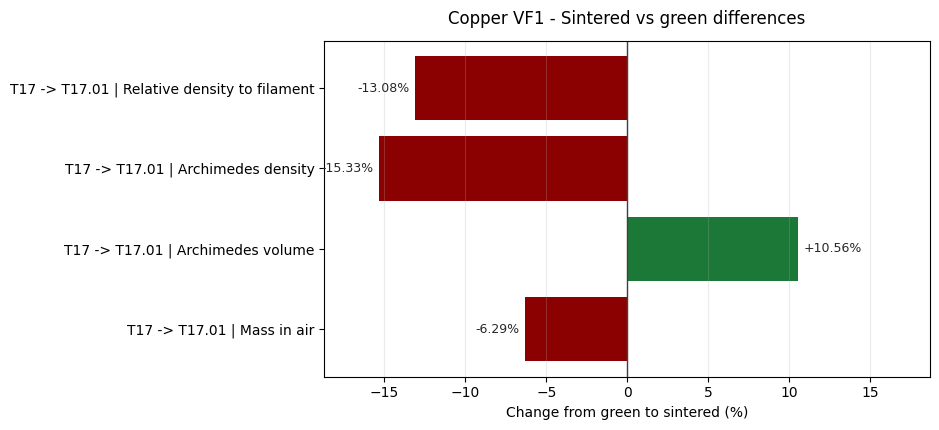

In [79]:
SINTERED_GREEN_METRICS = [
    ("weight_in_air_g", "Mass in air", "g"),
    ("volume_cm3", "Archimedes volume", "cm3"),
    ("density_g_cm3", "Archimedes density", "g/cm3"),
    ("relative_density_percent", "Relative density to filament", "%"),
    ("geometric_volume_cm3", "Geometric volume", "cm3"),
    ("geometric_density_g_cm3", "Geometric density", "g/cm3"),
    ("avg_density_g_cm3", "Average density", "g/cm3"),
    ("avg_relative_density_percent", "Average relative density to filament", "%"),
]

for column in ["specimen_state", "green_reference_run"]:
    if column not in copper_measurements.columns:
        copper_measurements[column] = pd.NA

copper_sintered_rows = copper_measurements[
    copper_measurements["specimen_state"].eq("sintered")
    & copper_measurements["green_reference_run"].notna()
].copy()

copper_sintered_green_differences = []
for _, sintered in copper_sintered_rows.iterrows():
    reference_run = sintered["green_reference_run"]
    green_matches = copper_measurements[copper_measurements["Run"].eq(reference_run)]
    if green_matches.empty:
        continue
    green = green_matches.iloc[0]
    for column, label, unit in SINTERED_GREEN_METRICS:
        if column not in copper_measurements.columns:
            continue
        green_value = pd.to_numeric(pd.Series([green.get(column)]), errors="coerce").iloc[0]
        sintered_value = pd.to_numeric(pd.Series([sintered.get(column)]), errors="coerce").iloc[0]
        if pd.isna(green_value) or pd.isna(sintered_value):
            continue
        delta = sintered_value - green_value
        percent_change = delta / green_value * 100 if green_value != 0 else np.nan
        copper_sintered_green_differences.append({
            "green_run": reference_run,
            "sintered_run": sintered["Run"],
            "metric": label,
            "unit": unit,
            "green_value": green_value,
            "sintered_value": sintered_value,
            "delta_sintered_minus_green": delta,
            "percent_change": percent_change,
        })

copper_sintered_green_differences = pd.DataFrame(
    copper_sintered_green_differences
)

if copper_sintered_green_differences.empty:
    display(pd.DataFrame([{
        "note": "No sintered specimens with green_reference_run are available yet."
    }]))
else:
    display(copper_sintered_green_differences.round({
        "green_value": 3,
        "sintered_value": 3,
        "delta_sintered_minus_green": 3,
        "percent_change": 2,
    }))

    plot_df = copper_sintered_green_differences.dropna(
        subset=["percent_change"]
    ).copy()
    plot_df["comparison"] = (
        plot_df["green_run"] + " -> " + plot_df["sintered_run"]
    )
    comparisons = plot_df["comparison"].drop_duplicates().tolist()
    fig_height = max(4.4, 0.42 * len(plot_df) + 1.2)
    fig, ax = plt.subplots(figsize=(9.5, fig_height))
    y_positions = np.arange(len(plot_df))
    colors = np.where(plot_df["percent_change"] >= 0, "#1b7837", "#8b0000")
    bars = ax.barh(y_positions, plot_df["percent_change"], color=colors)
    ax.axvline(0, color="0.25", linewidth=1.0)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        plot_df["comparison"] + " | " + plot_df["metric"]
    )
    ax.set_xlabel("Change from green to sintered (%)")
    ax.set_title("Copper - Sintered vs green differences", pad=12)
    ax.grid(axis="x", alpha=0.25)
    for bar, value in zip(bars, plot_df["percent_change"]):
        x_offset = 0.35 if value >= 0 else -0.35
        ha = "left" if value >= 0 else "right"
        ax.text(
            value + x_offset,
            bar.get_y() + bar.get_height() / 2,
            f"{value:+.2f}%",
            va="center",
            ha=ha,
            fontsize=9,
            color="0.15",
        )
    x_abs = plot_df["percent_change"].abs().max()
    ax.set_xlim(-x_abs * 1.22, x_abs * 1.22)
    plt.tight_layout()
    plt.show(block=False)


### Sintered-density Results and Green-density Comparison

All available Archimedes measurements are used. `T1`-`T4` and `T6`-`T13.2` have three measurements; `T5` has two. Filament, VFL_DS2, and VFL_DS4 are retained as filament-reference results but are excluded from the VF1 DoE model. Error bars show the specimen-specific sample standard deviation (`ddof=1`). Green density is represented by `avg_density_g_cm3`, consistent with the VF2 comparison.


,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,green_density_g_cm3,sintered_density_measurement_1_g_cm3,sintered_density_measurement_2_g_cm3,sintered_density_measurement_3_g_cm3,sintered_density_g_cm3,sintered_density_sd_g_cm3,sintered_n,sintered_relative_density_percent,density_increase_percent,sintered_mass_g,sintered_volume_cm3,condition,notes
0,FilamentVF1_DS1,NaN,NaN,NaN,NaN,NaN,NaN,7.13,7.20,NaN,7.165,0.050,2,79.967,NaN,1.00,0.14,in CO2,Filament reference; two Archimedes measurement...
1,VFL_DS2,NaN,NaN,NaN,NaN,NaN,NaN,7.07,NaN,NaN,7.070,NaN,1,78.906,NaN,1.70,0.24,DS_3,Filament reference; one Archimedes measurement...
2,VFL_DS4,NaN,NaN,NaN,NaN,NaN,NaN,8.54,NaN,NaN,8.540,NaN,1,95.312,NaN,1.54,0.18,DS_3,Filament reference; one Archimedes measurement...
3,T1,0.22,1.22,225.0,80.0,95.0,4.54,6.24,6.38,6.47,6.363,0.116,3,71.019,40.162,42.73,6.84,DS_4,Analysis uses all three supplied Archimedes me...
4,T2,0.20,1.22,215.0,60.0,95.0,4.64,6.22,6.30,6.35,6.290,0.066,3,70.201,35.560,42.50,6.83,DS_4,Analysis uses all three supplied Archimedes me...
5,T3,0.22,1.20,225.0,60.0,90.0,4.39,6.49,6.52,6.57,6.527,0.040,3,72.842,48.671,40.06,6.17,DS_4,Analysis uses all three supplied Archimedes me...
6,T4,0.18,1.22,220.0,80.0,90.0,4.40,6.23,6.27,6.33,6.277,0.050,3,70.052,42.652,40.40,6.48,DS_4,Analysis uses all three supplied Archimedes me...
7,T5,0.18,1.18,225.0,70.0,95.0,4.44,6.42,5.93,NaN,6.175,0.346,2,68.917,39.077,40.49,6.31,DS_4,Analysis uses both supplied Archimedes measure...
8,T6,0.22,1.18,215.0,80.0,92.5,4.37,6.37,6.48,6.52,6.457,0.078,3,72.061,47.750,39.97,6.27,DS_4,Analysis uses all three supplied Archimedes me...
9,T7,0.18,1.18,215.0,60.0,90.0,4.25,6.72,6.60,6.31,6.543,0.211,3,73.028,53.961,39.06,5.81,DS_5,Analysis uses all three supplied Archimedes me...


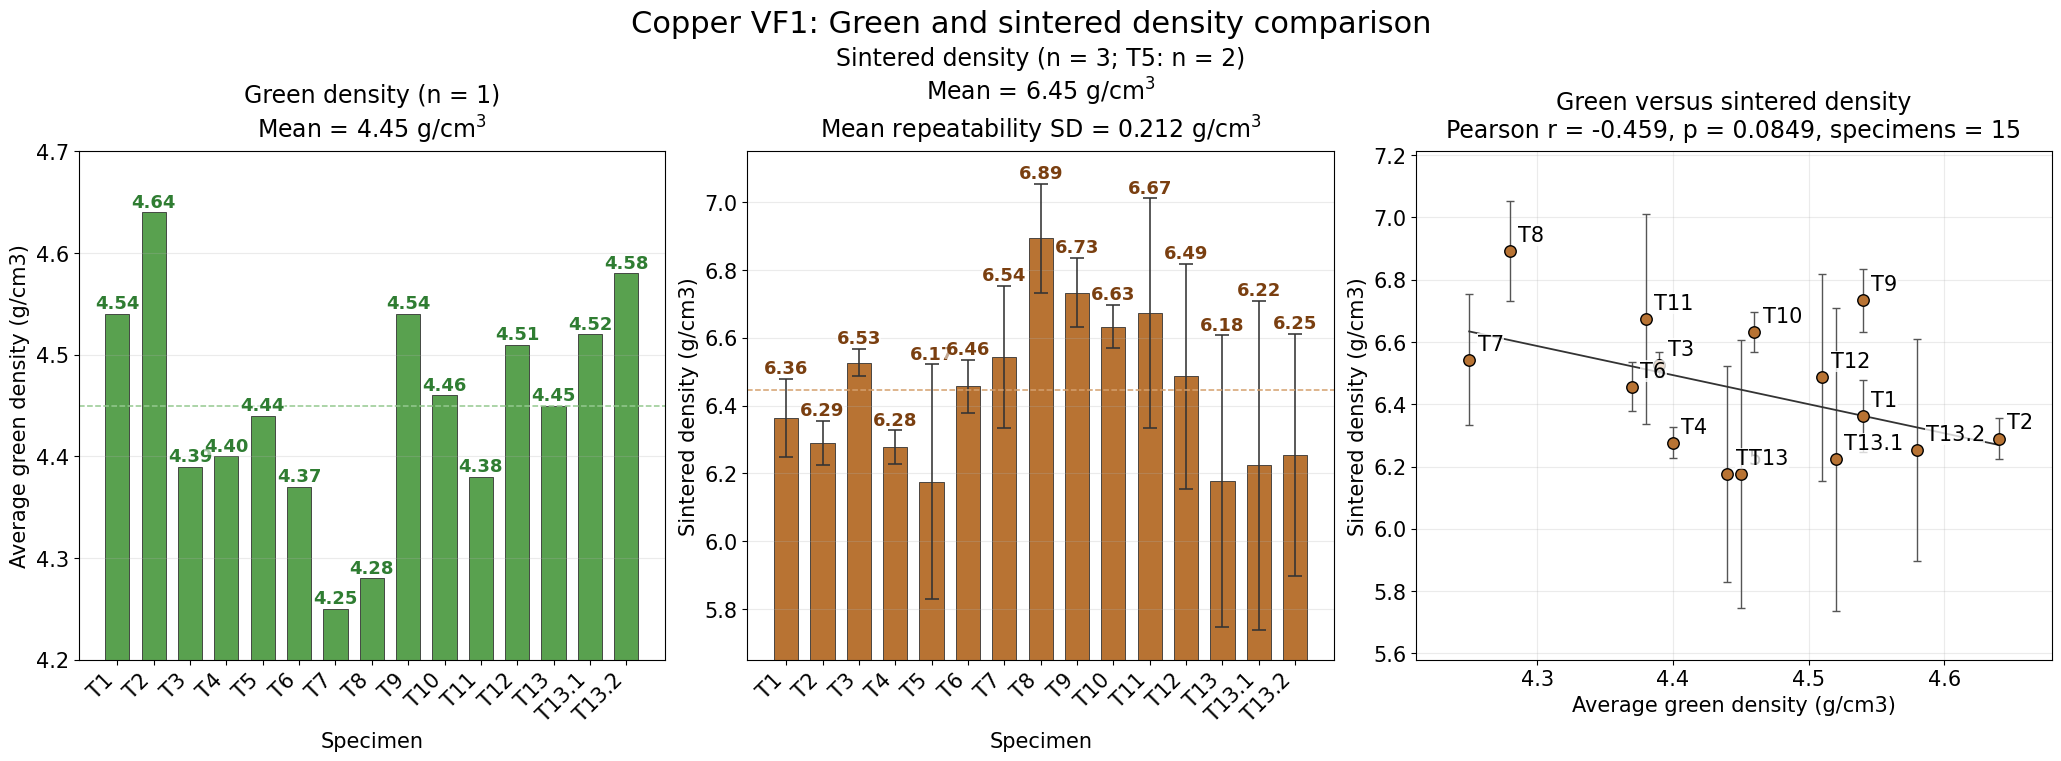

,Current result
Valid sintered observations,15
Requested main-effect parameters (intercept + 5 factors),6
Design-matrix rank,6
Residual degrees of freedom,9
Formal ANOVA,Estimable with residual error
Paired green/sintered observations,15
Green-sintered Pearson r,-0.459426
Green-sintered correlation p-value,0.084916


,Factor,Low level,High level,n low,n high,Mean at low,Mean at high,Unadjusted high-minus-low effect
0,Layer height,0.18,0.22,5,5,6.4430,6.5307,0.0877
1,Flow ratio,1.18,1.22,5,5,6.5403,6.4180,-0.1223
2,Nozzle temperature,215.00,225.00,5,5,6.5393,6.4890,-0.0503
3,Speed,60.00,80.00,5,5,6.4960,6.5447,0.0487
4,Infill,90.00,95.00,5,5,6.5827,6.4390,-0.1437


,term,coefficient,standard_error,standardized_effect,t_value,F_value,p_value,absolute_standardized_effect,absolute_coefficient
0,Intercept,6.44700,0.06436,100.16907,100.16907,10033.84243,0.00000,100.16907,6.44700
1,A_layer_height_mm,0.04383,0.07883,0.55608,0.55608,0.30922,0.59171,0.55608,0.04383
2,B_flow_ratio,-0.06117,0.07883,-0.77597,-0.77597,0.60213,0.45767,0.77597,0.06117
3,C_nozzle_temp_C,-0.02517,0.07883,-0.31927,-0.31927,0.10193,0.75681,0.31927,0.02517
4,D_speed_mm_s,0.02433,0.07883,0.30870,0.30870,0.09529,0.76458,0.30870,0.02433
5,E_infill_percent,-0.07183,0.07883,-0.91129,-0.91129,0.83045,0.38590,0.91129,0.07183


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,5,0.12048,0.02410,0.38781,0.84532
1,Residual,9,0.55922,0.06214,NaN,NaN
2,Total,14,0.67970,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value
1,A_layer_height_mm,0.04383,0.07883,0.55608,0.30922,0.59171
2,B_flow_ratio,-0.06117,0.07883,-0.77597,0.60213,0.45767
3,C_nozzle_temp_C,-0.02517,0.07883,-0.31927,0.10193,0.75681
4,D_speed_mm_s,0.02433,0.07883,0.30870,0.09529,0.76458
5,E_infill_percent,-0.07183,0.07883,-0.91129,0.83045,0.38590


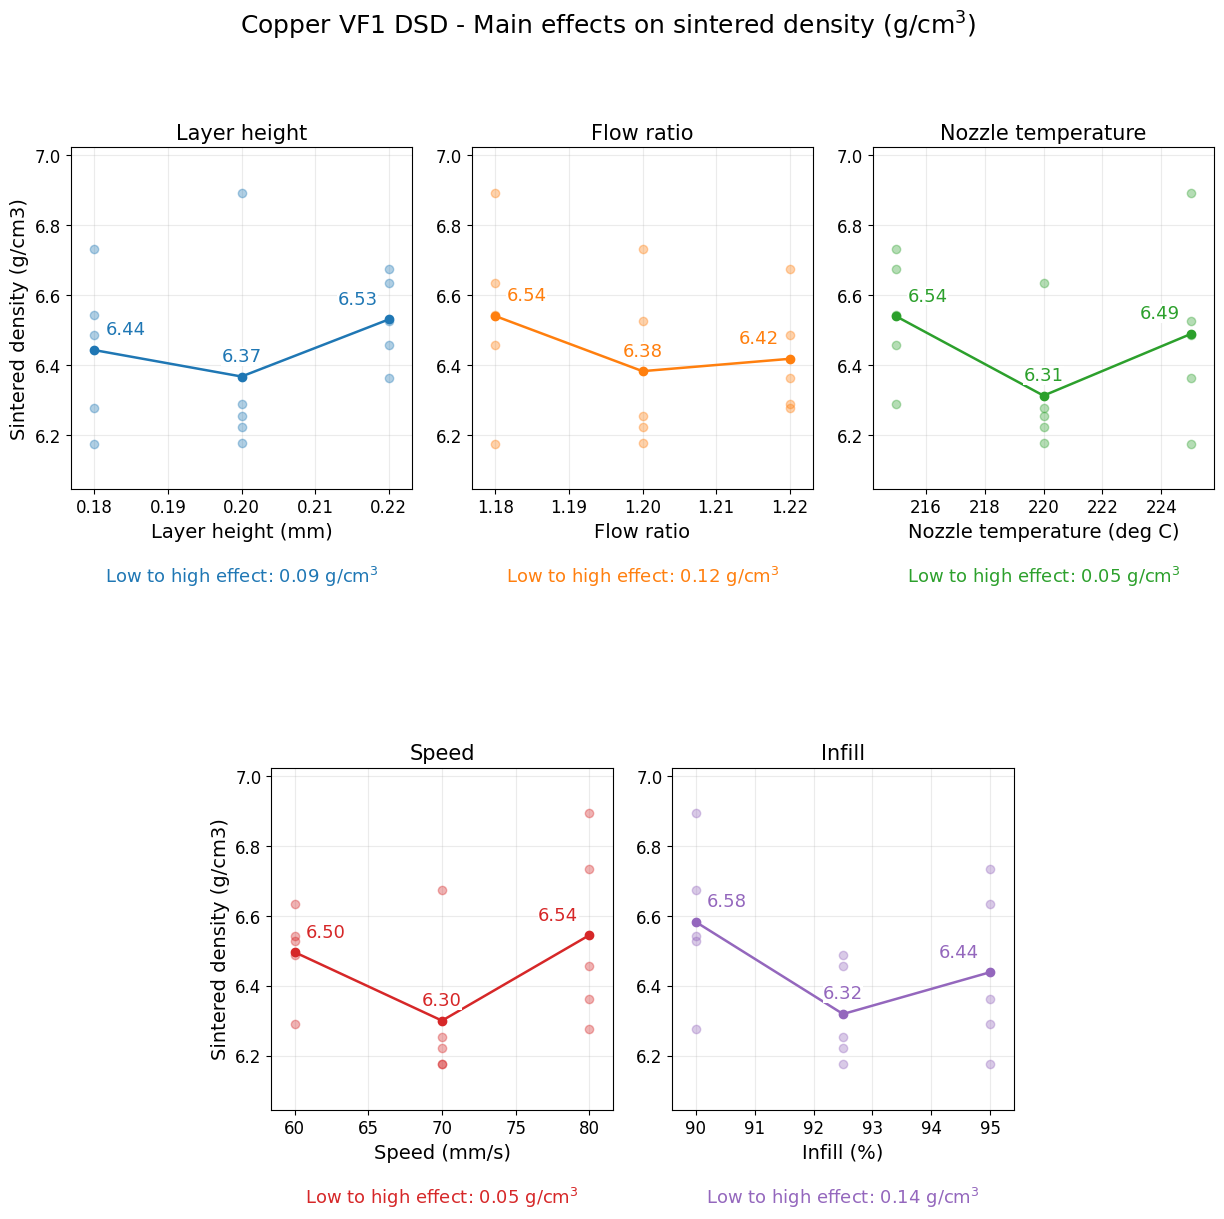

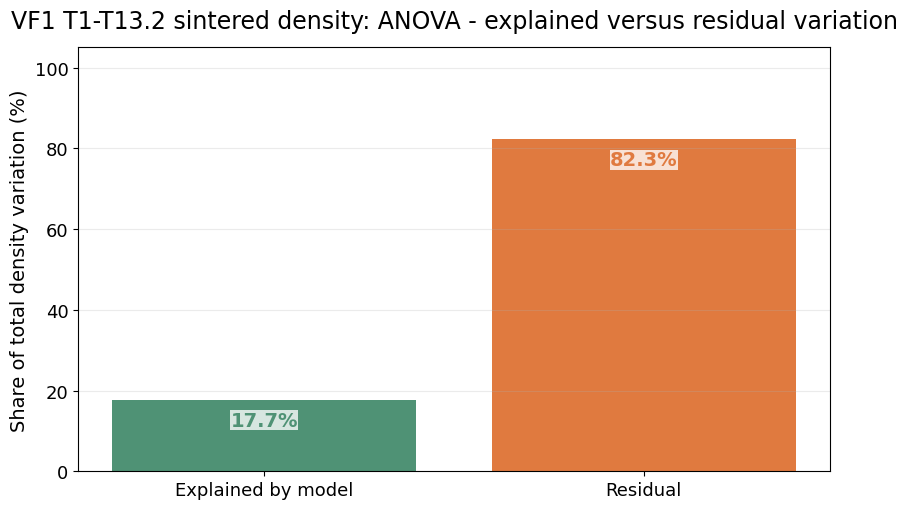

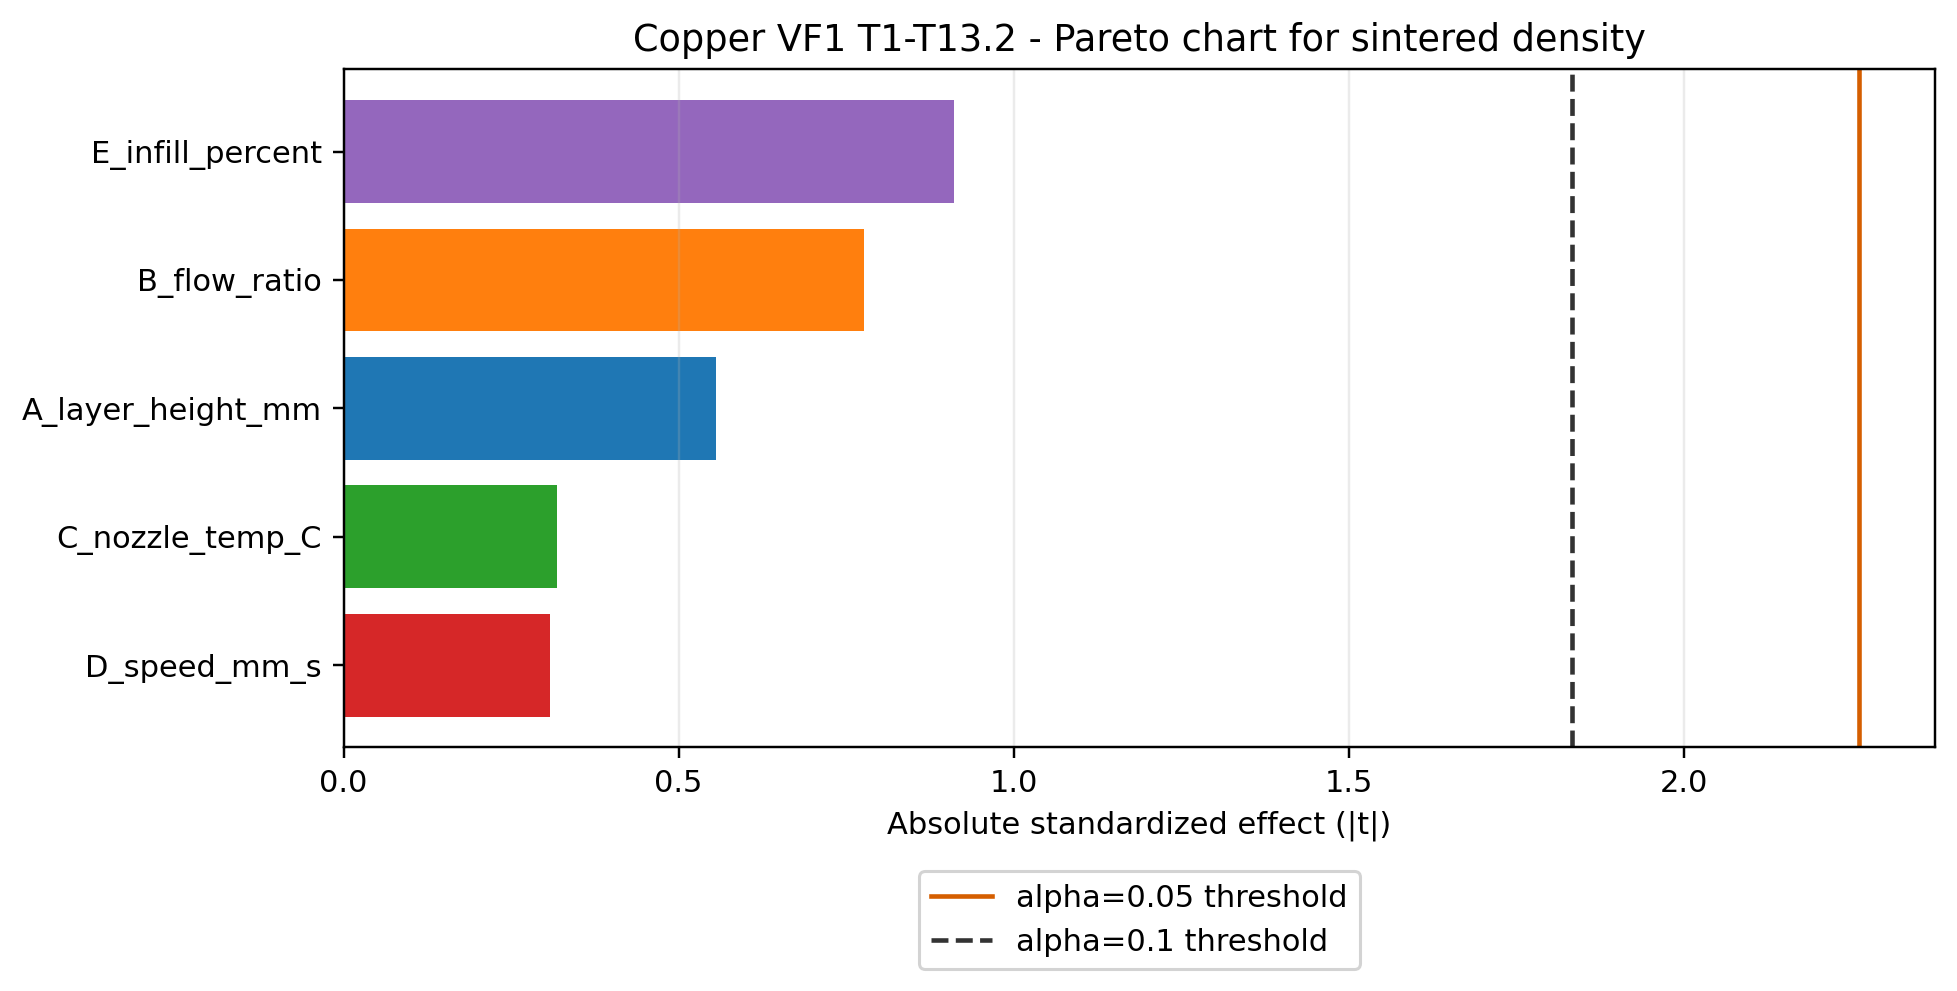

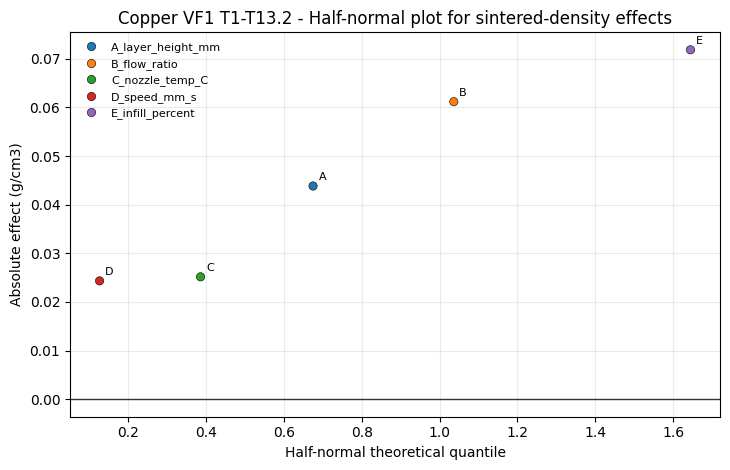

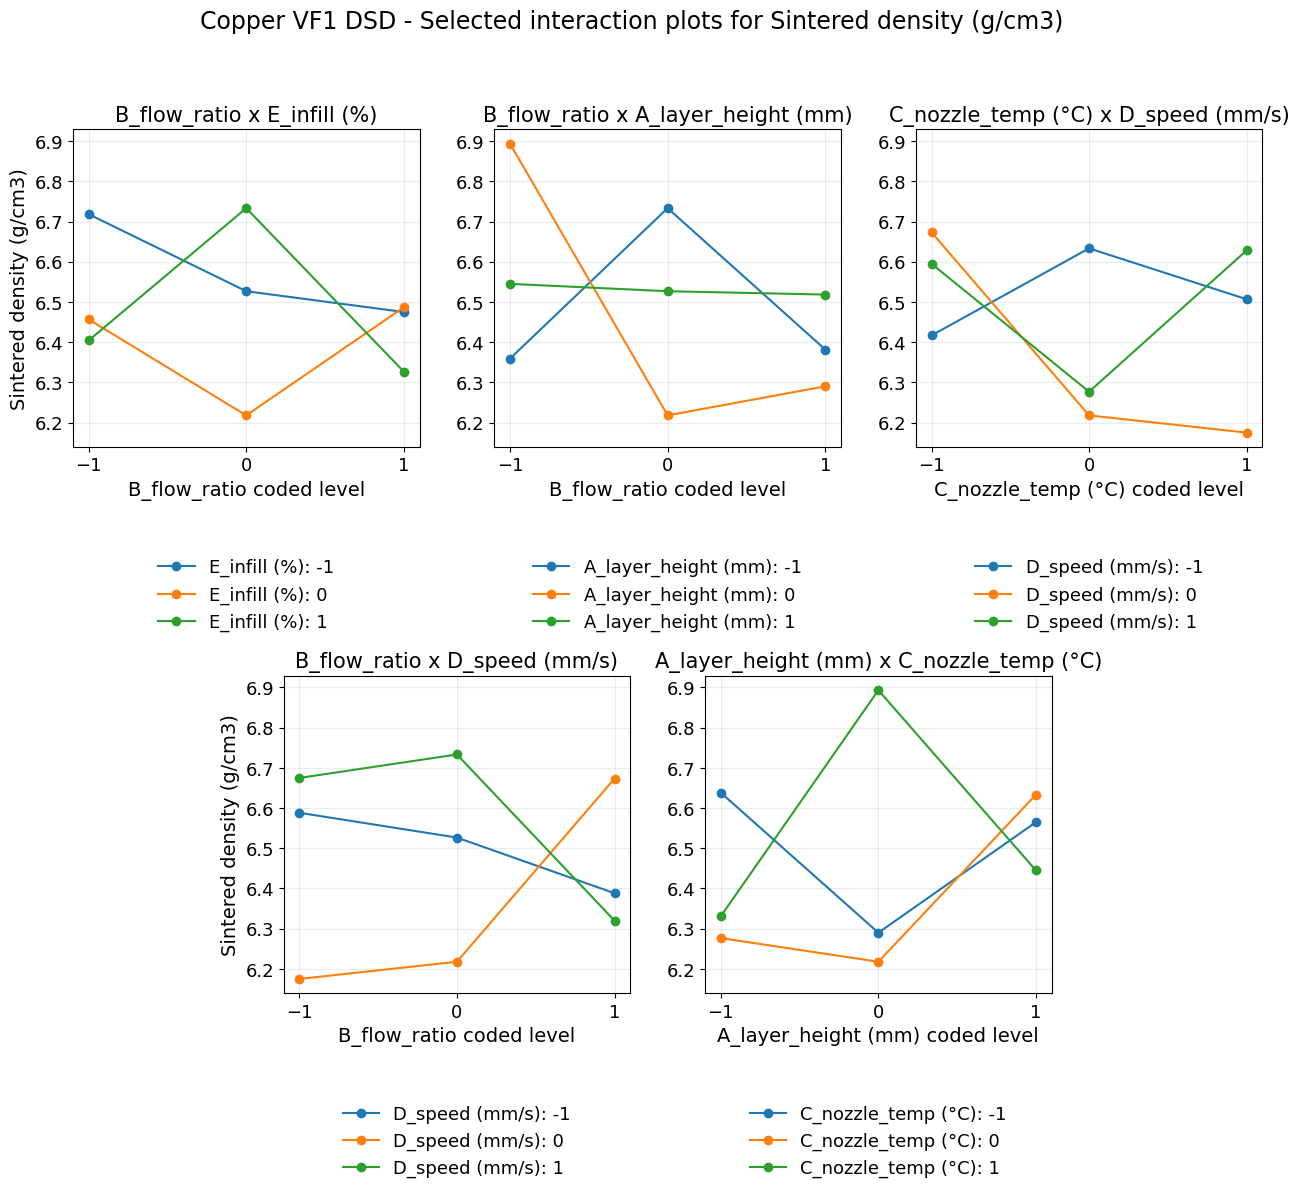

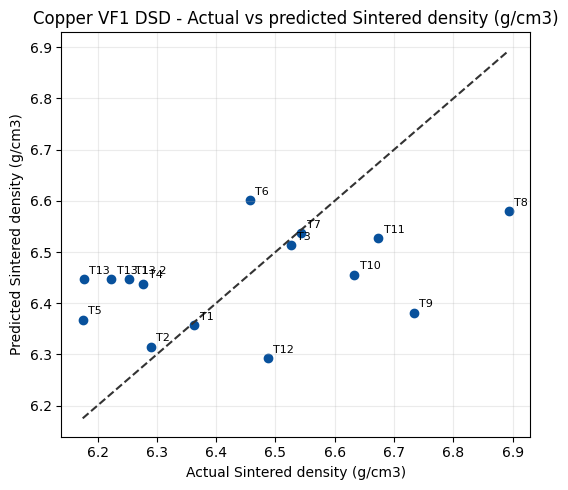

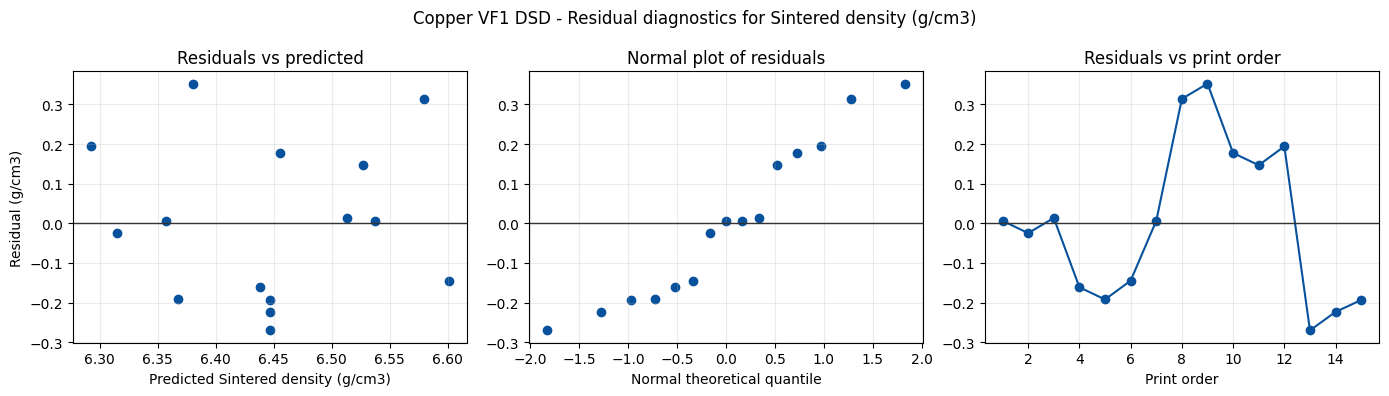

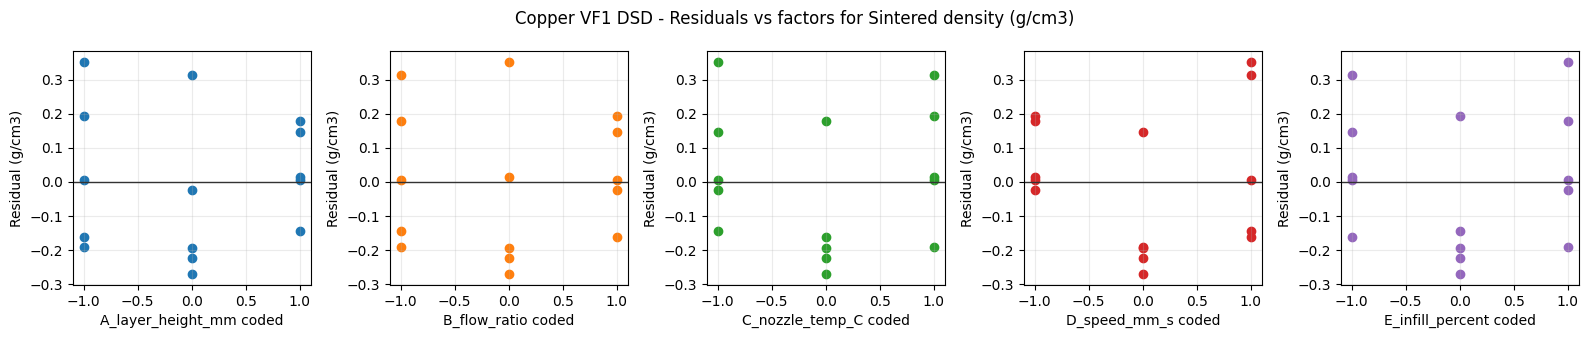

In [80]:
from scipy.stats import pearsonr

VF1_SINTERED_PATH = Path(
    "doe_matrices/Copper_VirtualFoundry1/"
    "copper_virtualfoundry1_sintered_measurements.csv"
)
if not VF1_SINTERED_PATH.exists():
    VF1_SINTERED_PATH = Path("3D_Printing_Project") / VF1_SINTERED_PATH

vf1_sintered_results = pd.read_csv(VF1_SINTERED_PATH)
vf1_sintered_numeric_columns = [
    "sintered_mass_g",
    "sintered_volume_measurement_1_cm3",
    "sintered_volume_cm3",
    "sintered_density_measurement_1_g_cm3",
    "sintered_density_measurement_2_g_cm3",
    "sintered_density_measurement_3_g_cm3",
    "sintered_density_g_cm3",
    "sintered_density_sd_g_cm3",
    "sintered_relative_density_percent",
    "sintered_relative_density_sd_percentage_points",
]
for column in vf1_sintered_numeric_columns:
    vf1_sintered_results[column] = pd.to_numeric(
        vf1_sintered_results[column], errors="coerce"
    )
vf1_sintered_replicates = vf1_sintered_results[[
    "sintered_density_measurement_1_g_cm3",
    "sintered_density_measurement_2_g_cm3",
    "sintered_density_measurement_3_g_cm3",
]].copy()
vf1_calculated_sintered_mean = vf1_sintered_replicates.mean(axis=1)
vf1_calculated_sintered_sd = vf1_sintered_replicates.std(axis=1, ddof=1)
vf1_sintered_replicate_counts = vf1_sintered_replicates.notna().sum(axis=1)
vf1_sintered_results["sintered_n"] = vf1_sintered_replicate_counts
vf1_sintered_results["sintered_density_g_cm3"] = (
    vf1_calculated_sintered_mean.combine_first(
        vf1_sintered_results["sintered_density_g_cm3"]
    )
)
vf1_sintered_results["sintered_density_sd_g_cm3"] = (
    vf1_sintered_results["sintered_density_sd_g_cm3"].combine_first(
        vf1_calculated_sintered_sd
    )
)
vf1_sintered_results["sintered_relative_density_percent"] = (
    vf1_sintered_results["sintered_density_g_cm3"] / 8.96 * 100.0
)
vf1_sintered_results["sintered_relative_density_sd_percentage_points"] = (
    vf1_sintered_results["sintered_density_sd_g_cm3"] / 8.96 * 100.0
)

vf1_green_density_columns = ["density_g_cm3", "geometric_density_g_cm3"]
vf1_green_results = copper_measurements[[
    "Run", "avg_density_g_cm3", *vf1_green_density_columns
]].copy()
for column in ["avg_density_g_cm3", *vf1_green_density_columns]:
    vf1_green_results[column] = pd.to_numeric(
        vf1_green_results[column], errors="coerce"
    )
vf1_green_results["avg_density_g_cm3"] = (
    vf1_green_results["avg_density_g_cm3"].combine_first(
        vf1_green_results[vf1_green_density_columns].mean(axis=1)
    )
)
vf1_factor_settings = copper_augmented_response_table[[
    "Run", *copper_factor_names
]].copy()
for factor_name in copper_factor_names:
    vf1_factor_settings[factor_name] = vf1_factor_settings[factor_name].map(
        copper_factor_levels[factor_name]
    )
vf1_sintered_density_results = (
    vf1_sintered_results
    .merge(vf1_factor_settings, on="Run", how="left", validate="one_to_one")
    .merge(vf1_green_results, on="Run", how="left", validate="one_to_one")
    .rename(columns={"avg_density_g_cm3": "green_density_g_cm3"})
)
vf1_sintered_density_results["density_increase_percent"] = (
    100
    * (
        vf1_sintered_density_results["sintered_density_g_cm3"]
        - vf1_sintered_density_results["green_density_g_cm3"]
    )
    / vf1_sintered_density_results["green_density_g_cm3"]
)
display(vf1_sintered_density_results[[
    "Run", *copper_factor_names,
    "green_density_g_cm3",
    "sintered_density_measurement_1_g_cm3",
    "sintered_density_measurement_2_g_cm3",
    "sintered_density_measurement_3_g_cm3",
    "sintered_density_g_cm3", "sintered_density_sd_g_cm3", "sintered_n",
    "sintered_relative_density_percent", "density_increase_percent",
    "sintered_mass_g", "sintered_volume_cm3", "condition", "notes",
]].round(3))

vf1_paired_density = vf1_sintered_density_results.dropna(
    subset=["green_density_g_cm3", "sintered_density_g_cm3"]
).copy()
vf1_green_sintered_r, vf1_green_sintered_p = pearsonr(
    vf1_paired_density["green_density_g_cm3"],
    vf1_paired_density["sintered_density_g_cm3"],
)

DENSITY_TEXT_SIZE = 15
DENSITY_VALUE_SIZE = 13
DENSITY_PANEL_TITLE_SIZE = 17
DENSITY_MAIN_TITLE_SIZE = 22

figure, axes = plt.subplots(
    1, 3, figsize=(20.5, 7.5), constrained_layout=True,
    gridspec_kw={"width_ratios": [1.2, 1.2, 1.3]},
)
positions = np.arange(len(vf1_paired_density)) * 1.08
labels = vf1_paired_density["Run"].tolist()
green_values = vf1_paired_density["green_density_g_cm3"].to_numpy()
sintered_values = vf1_paired_density["sintered_density_g_cm3"].to_numpy()
sintered_sd_values = vf1_paired_density[
    "sintered_density_sd_g_cm3"
].fillna(0.0).to_numpy()
sintered_mean_repeatability_sd = vf1_paired_density["sintered_density_sd_g_cm3"].mean()
paired_replicate_counts = vf1_paired_density.set_index("Run")["sintered_n"]
modal_replicate_count = int(paired_replicate_counts.mode().iloc[0])
vf1_sintered_sample_note = f"n = {modal_replicate_count}"
replicate_exceptions = paired_replicate_counts[
    paired_replicate_counts != modal_replicate_count
]
if not replicate_exceptions.empty:
    vf1_sintered_sample_note += "; " + "; ".join(
        f"{run}: n = {int(count)}"
        for run, count in replicate_exceptions.items()
    )

def plot_density_bars(
    axis, values, color, mean_color, label_color, title, y_label, errors=None,
    mean_repeatability_sd=None, value_fontsize=DENSITY_VALUE_SIZE, bar_width=0.72,
):
    error_values = (
        np.zeros_like(values, dtype=float)
        if errors is None else np.asarray(errors, dtype=float)
    )
    axis_min = np.floor(
        ((values - error_values).min() - 0.04) / 0.05
    ) * 0.05
    axis_max = np.ceil(
        ((values + error_values).max() + 0.05) / 0.05
    ) * 0.05
    bars = axis.bar(
        positions, values - axis_min, bottom=axis_min, width=bar_width,
        color=color, edgecolor="#333333", linewidth=0.6,
        yerr=None if errors is None else error_values,
        capsize=5 if errors is not None else 0,
        error_kw={"elinewidth": 1.15, "ecolor": "#333333", "capthick": 1.15},
    )
    axis.axhline(values.mean(), color=mean_color, linestyle="--", linewidth=1.1)
    for bar, value, error_value in zip(bars, values, error_values):
        axis.annotate(
            f"{value:.2f}",
            (bar.get_x() + bar.get_width() / 2, value + error_value),
            xytext=(0, 1), textcoords="offset points", ha="center", va="bottom",
            fontsize=value_fontsize, fontweight="bold", color=label_color, zorder=6,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.55, "pad": 0.20},
        )
    axis.set_ylim(axis_min, axis_max)
    axis.set_xticks(
        positions, labels, rotation=45, ha="right", fontsize=DENSITY_TEXT_SIZE
    )
    axis.set_xlabel("Specimen", fontsize=DENSITY_TEXT_SIZE)
    axis.set_ylabel(y_label, fontsize=DENSITY_TEXT_SIZE)
    axis.tick_params(axis="y", labelsize=DENSITY_TEXT_SIZE)
    title_text = f"{title}\nMean = {values.mean():.2f} g/cm$^3$"
    if mean_repeatability_sd is not None and np.isfinite(mean_repeatability_sd):
        title_text += (
            f"\nMean repeatability SD = {mean_repeatability_sd:.3f} g/cm$^3$"
        )
    axis.set_title(title_text, pad=10, fontsize=DENSITY_PANEL_TITLE_SIZE)
    axis.grid(axis="y", alpha=0.25)

plot_density_bars(
    axes[0], green_values, "#59a14f", "#94c990", "#2f7d32",
    "Green density (n = 1)", "Average green density (g/cm3)",
)
plot_density_bars(
    axes[1], sintered_values, "#b87333", "#d4a06e", "#7a3f10",
    f"Sintered density ({vf1_sintered_sample_note})",
    "Sintered density (g/cm3)",
    errors=sintered_sd_values, mean_repeatability_sd=sintered_mean_repeatability_sd,
)

axes[2].scatter(
    green_values, sintered_values, s=68,
    color="#b87333", edgecolor="black", zorder=3,
)
axes[2].errorbar(
    green_values, sintered_values, yerr=sintered_sd_values,
    fmt="none", ecolor="#555555", elinewidth=1.0, capsize=3, zorder=2,
)
for _, row in vf1_paired_density.iterrows():
    axes[2].annotate(
        row["Run"],
        (row["green_density_g_cm3"], row["sintered_density_g_cm3"]),
        xytext=(6, 7), textcoords="offset points", fontsize=DENSITY_TEXT_SIZE,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78, "pad": 0.5},
    )
correlation_slope, correlation_intercept = np.polyfit(
    green_values, sintered_values, 1
)
correlation_x = np.linspace(green_values.min(), green_values.max(), 100)
axes[2].plot(
    correlation_x,
    correlation_slope * correlation_x + correlation_intercept,
    color="#333333", linewidth=1.3,
)
axes[2].set_xlabel("Average green density (g/cm3)", fontsize=DENSITY_TEXT_SIZE)
axes[2].set_ylabel("Sintered density (g/cm3)", fontsize=DENSITY_TEXT_SIZE)
axes[2].set_title(
    "Green versus sintered density\n"
    f"Pearson r = {vf1_green_sintered_r:.3f}, "
    f"p = {vf1_green_sintered_p:.4f}, specimens = {len(vf1_paired_density)}",
    fontsize=DENSITY_PANEL_TITLE_SIZE, pad=10,
)
axes[2].tick_params(axis="both", labelsize=DENSITY_TEXT_SIZE)
axes[2].grid(alpha=0.25)
axes[2].margins(x=0.10, y=0.12)
figure.suptitle(
    "Copper VF1: Green and sintered density comparison",
    fontsize=DENSITY_MAIN_TITLE_SIZE,
)
plt.show()

vf1_valid_sintered = vf1_sintered_density_results.dropna(
    subset=["sintered_density_g_cm3", *copper_factor_names]
).copy()
vf1_design_columns = [np.ones(len(vf1_valid_sintered))]
for factor_name in copper_factor_names:
    coded_map = {
        copper_factor_levels[factor_name][-1]: -1,
        copper_factor_levels[factor_name][0]: 0,
        copper_factor_levels[factor_name][1]: 1,
    }
    coded_column = f"{factor_name}_coded_sintered"
    vf1_valid_sintered[coded_column] = vf1_valid_sintered[factor_name].map(coded_map)
    vf1_design_columns.append(vf1_valid_sintered[coded_column].to_numpy(dtype=float))
vf1_sintered_design = np.column_stack(vf1_design_columns)
vf1_sintered_rank = np.linalg.matrix_rank(vf1_sintered_design)
vf1_sintered_residual_df = len(vf1_valid_sintered) - vf1_sintered_rank

vf1_unadjusted_effect_rows = []
for factor in copper_factors:
    factor_name = factor["name"]
    low_value = copper_factor_levels[factor_name][-1]
    high_value = copper_factor_levels[factor_name][1]
    low_density = vf1_valid_sintered.loc[
        vf1_valid_sintered[factor_name] == low_value, "sintered_density_g_cm3"
    ]
    high_density = vf1_valid_sintered.loc[
        vf1_valid_sintered[factor_name] == high_value, "sintered_density_g_cm3"
    ]
    vf1_unadjusted_effect_rows.append({
        "Factor": factor["display_name"],
        "Low level": low_value,
        "High level": high_value,
        "n low": len(low_density),
        "n high": len(high_density),
        "Mean at low": low_density.mean(),
        "Mean at high": high_density.mean(),
        "Unadjusted high-minus-low effect": high_density.mean() - low_density.mean(),
    })
vf1_unadjusted_effects = pd.DataFrame(vf1_unadjusted_effect_rows)

vf1_sintered_model_table = (
    copper_augmented_response_table[["Run", *copper_factor_names]]
    .merge(
        vf1_sintered_results[["Run", "sintered_density_g_cm3"]],
        on="Run", how="left", validate="one_to_one",
    )
)
vf1_sintered_response_model = None
vf1_sintered_anova_table = None
if vf1_sintered_residual_df > 0:
    vf1_sintered_response_model = fit_copper_response_model(
        vf1_sintered_model_table,
        response="sintered_density_g_cm3",
        terms=main_effect_terms,
    )
    vf1_sintered_anova_table = build_copper_anova_table(
        vf1_sintered_response_model
    )

vf1_estimability_summary = pd.Series({
    "Valid sintered observations": len(vf1_valid_sintered),
    "Requested main-effect parameters (intercept + 5 factors)": 6,
    "Design-matrix rank": vf1_sintered_rank,
    "Residual degrees of freedom": vf1_sintered_residual_df,
    "Formal ANOVA": (
        "Estimable with residual error"
        if vf1_sintered_residual_df > 0
        else "Not estimable with current data"
    ),
    "Paired green/sintered observations": len(vf1_paired_density),
    "Green-sintered Pearson r": vf1_green_sintered_r,
    "Green-sintered correlation p-value": vf1_green_sintered_p,
}, name="Current result")
display(vf1_estimability_summary.to_frame())
display(vf1_unadjusted_effects.round(4))
if vf1_sintered_response_model is not None:
    display(vf1_sintered_response_model["coefficient_df"].round(5))
    display(vf1_sintered_anova_table.round(5))
    display(
        build_copper_term_significance_table(
            vf1_sintered_response_model
        ).round(5)
    )

figure = plt.figure(figsize=(12.5, 12.9))
grid = figure.add_gridspec(2, 6, hspace=0.42, wspace=0.42)
factor_axes = [
    figure.add_subplot(grid[0, 0:2]),
    figure.add_subplot(grid[0, 2:4]),
    figure.add_subplot(grid[0, 4:6]),
    figure.add_subplot(grid[1, 1:3]),
    figure.add_subplot(grid[1, 3:5]),
]
factor_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
all_factor_means = []
for axis, factor, color in zip(factor_axes, copper_factors, factor_colors):
    factor_name = factor["name"]
    grouped = (
        vf1_valid_sintered.groupby(factor_name, as_index=False)["sintered_density_g_cm3"]
        .agg(["mean", "count"])
        .reset_index()
    )
    all_factor_means.extend(grouped["mean"].tolist())
    axis.scatter(
        vf1_valid_sintered[factor_name],
        vf1_valid_sintered["sintered_density_g_cm3"],
        color=color, alpha=0.35, s=36, zorder=3,
    )
    axis.plot(grouped[factor_name], grouped["mean"], color=color, marker="o", linewidth=1.8)
    for point_index, (factor_value, mean_value) in enumerate(
        zip(grouped[factor_name], grouped["mean"])
    ):
        is_first = point_index == 0
        is_last = point_index == len(grouped) - 1
        label_x_offset = 8 if is_first else (-8 if is_last else 0)
        label_alignment = "left" if is_first else ("right" if is_last else "center")
        axis.annotate(
            f"{mean_value:.2f}", (factor_value, mean_value),
            xytext=(label_x_offset, 11), textcoords="offset points",
            ha=label_alignment, fontsize=13, color=color, zorder=6,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 1.0, "pad": 0.32},
        )
    effect_row = vf1_unadjusted_effects.loc[
        vf1_unadjusted_effects["Factor"] == factor["display_name"]
    ].iloc[0]
    axis.text(
        0.5, -0.22,
        f"Low to high effect: {abs(effect_row['Unadjusted high-minus-low effect']):.2f} g/cm$^3$",
        transform=axis.transAxes, ha="center", va="top", fontsize=13, color=color,
    )
    factor_unit = factor["unit"]
    factor_axis_label = factor["display_name"]
    if factor_unit:
        factor_axis_label += f" ({factor_unit})"
    axis.set_xlabel(factor_axis_label, fontsize=14)
    axis.set_title(factor["display_name"], fontsize=15)
    axis.tick_params(axis="both", labelsize=12)
    axis.margins(x=0.08)
    axis.set_box_aspect(1)
    axis.grid(alpha=0.25)
for axis in (factor_axes[0], factor_axes[3]):
    axis.set_ylabel("Sintered density (g/cm3)", fontsize=14)
factor_plot_values = np.concatenate([
    vf1_valid_sintered["sintered_density_g_cm3"].to_numpy(),
    np.asarray(all_factor_means),
])
factor_padding = max(0.04, 0.18 * np.ptp(factor_plot_values))
for axis in factor_axes:
    axis.set_ylim(
        factor_plot_values.min() - factor_padding,
        factor_plot_values.max() + factor_padding,
    )
figure.suptitle(
    "Copper VF1 DSD - Main effects on sintered density (g/cm$^3$)",
    y=0.98, fontsize=18,
)
figure.subplots_adjust(left=0.07, right=0.985, bottom=0.09, top=0.91)
plt.show()

if vf1_sintered_response_model is not None:
    plot_copper_anova(
        vf1_sintered_anova_table,
        response="sintered_density_g_cm3",
        title="VF1 T1-T13.2 sintered density: ANOVA - explained versus residual variation",
        variation_percent=True,
    )
    plot_copper_pareto(
        vf1_sintered_response_model,
        title="Copper VF1 T1-T13.2 - Pareto chart for sintered density",
        alpha=SIGNIFICANCE_ALPHA,
        secondary_alpha=0.10,
    )
    plot_copper_normal_effects(
        vf1_sintered_response_model,
        half_normal=True,
        title="Copper VF1 T1-T13.2 - Half-normal plot for sintered-density effects",
    )
    plot_copper_interactions(
        vf1_sintered_model_table,
        response="sintered_density_g_cm3",
        interaction_pairs=COPPER_SELECTED_INTERACTIONS,
        figsize=(13, 12),
        font_size=14,
    )
    plot_copper_actual_vs_predicted(vf1_sintered_response_model)
    plot_copper_residuals(vf1_sintered_response_model, copper_factor_names)

if vf1_sintered_residual_df <= 0:
    print(
        "Formal five-factor ANOVA was not calculated: five valid sintered-density "
        "observations cannot estimate an intercept, five main effects, and residual error. "
        "At least two additional appropriately chosen sintered runs are required for one "
        "residual degree of freedom; completing the planned DSD provides a defensible analysis."
    )